# 08 — Does SPP1 suppress NK cells through tumour integrin αvβ3 → NF-κB → TGF-β1?

**The mechanism under test** (Shen et al., *Apoptosis* 2026, 31:155; HNSCC):

| link | Shen's evidence | what single-cell RNA here can test | § |
|---|---|---|---|
| S1 **tumour-derived** OPN (SPP1) | OPN-KO / OE tumour lines; tumour SPP1 vs NK abundance in TCGA bulk | is `Spp1` in tumour cells their own transcript, and how much of the tissue's Spp1 is tumour vs macrophage? | 3 |
| S2 OPN binds **integrin αvβ3 on tumour cells**, *not* CD44 | blocking antibodies (α2, αvβ1, αvβ5, CD44, αvβ3); co-IP | are `Itgav` **and** `Itgb3` detectable in tumour cells, and co-detected? | 4 |
| S3 αvβ3 → **NF-κB** (p-p65, IκBα degradation) → **TGF-β1** | western blot, ELISA, PDTC | do receptor-positive tumour cells carry more NF-κB-target and `Tgfb1` transcript? is tumour `Tgfb1` intrinsic? | 4 |
| S4 TGF-β1 **suppresses NK** activation (NKG2D, NKp30, NKp46, CD107a, IFN-γ) | SB525334 rescue in vitro / in vivo | do NK cells show a TGF-β response, and does it track a lower effector program? | 5 |
| S5 the chain in tissue | — | across mice, does higher putative SPP1 → integrin → TGF-β activity go with weaker NK effector programs, after treatment, site and mouse? | 6 |

**Not assumed:** that SPP1–CD44 is the operative pathway. Shen found αvβ3, not CD44, on tumour
cells; the SPP1 → CD44 potential is carried alongside as a **comparator**, never as the
hypothesis. Two details of the paper matter for reading these data:
* Shen's single-cell panel (Fig. 6C) plots **ITGB3BP** — integrin-β3-binding protein, a nuclear
  co-regulator, not the β3 integrin — so their single-cell data never showed `ITGB3` on tumour
  cells. Here `Itgb3` itself is used.
* Shen report recombinant OPN had **no direct effect on NK cells** in vitro, so the mechanism is
  indirect by design: a null NK–Spp1 correlation is expected under it, and only the tumour →
  TGF-β → NK chain is diagnostic.

**What single-cell RNA cannot measure:** OPN protein, integrin activation or ligand binding,
p65 phosphorylation, IκBα degradation, latent-TGF-β activation and secretion, NK degranulation or
killing. Every link here is **transcriptional potential**; integrin αvβ3 also activates latent
TGF-β (Reactome lists `Itgav`/`Itgb3` inside "TGF-β receptor signalling activates SMADs"), so
integrin transcript is not specific to OPN signalling.

**Design rules** are those of `07`: mouse = unit (site-centred mouse means; within-mouse Tu1 − Tu2
separately), exact relabelling for treatment effects, Freedman–Lane for associations,
BH within pre-specified families, leave-one-mouse-out everywhere, minimum cell counts and
detectable effects for NK / CD8 T, and an ambient-RNA check for every tumour-cell transcript.

## 1. Config and figure style (the conventions of Figures 1–5, shared with `07`)

In [1]:
import warnings; warnings.filterwarnings("ignore")
import json, itertools, time, logging
from pathlib import Path
import numpy as np, pandas as pd, h5py, anndata as ad
import scipy.sparse as sp
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
logging.disable(logging.WARNING)

pd.set_option("display.width", 300); pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 500); pd.set_option("display.max_colwidth", 70)
_HPC = Path("/coh_labs/yunroseli/Jona/CAR-T"); _LOC = Path("/Users/janzules/Roselab/Spatial/CAR_T")
PROJ = _LOC if _LOC.exists() else _HPC
SC_REF = (PROJ/"data/sc-reference/annotation_v4.h5ad" if PROJ is _LOC
          else PROJ/"data/zarr/fullDataset/annotating_references/annotation_v4.h5ad")
GMT_DIR = PROJ/"data/references/pathways"
OUT = PROJ/"results/mhc_cytotox"; T08 = OUT/"08_spp1_tgfb"; FIG = OUT/"figures"
T08.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)
assert (OUT/"pseudobulk_counts.parquet").exists(), "run 00 first"

MIN_CELLS, MIN_CELLS_DET, MIN_CELLS_STATE = 10, 8, 20
N_PERM, N_BOOT, N_RANDOM, SEED = 5000, 2000, 200, 0
rng = np.random.default_rng(SEED)

from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
# Figures 1-5 conventions (code/mhcCytotoxFigures): colour = CAR background, open marker = RT, shape = tumour site
INK, INK2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
C_PSCA, C_TAG72, C_NOTX = "#eb6834", "#2a78d6", "#898781"
CAR_COL = {"PSCA": C_PSCA, "TAG72": C_TAG72, "none": C_NOTX}
CAR_OF = {"NoTx": "none", "CyT72": "TAG72", "CyPSCA": "PSCA", "RTCyT72": "TAG72", "RTCyPSCA": "PSCA"}
DIV = LinearSegmentedColormap.from_list("div", ["#104281", "#1c5cab", "#3987e5", "#86b6ef", "#cde2fb", "#f0efec",
                                                "#fad6d2", "#ea9a93", "#d75853", "#9e3432", "#762221"])
SEQ = LinearSegmentedColormap.from_list("seq", ["#d9dbfc", "#b6b7f3", "#918fe9", "#7067da", "#5342ba",
                                                "#382887", "#231859"])
SITE_MARK = {1: "o", 2: "s"}
NAME = {"Classical_Mono": "Classical mono", "Nonclassical_Mono": "Non-classical mono", "IFN_stimulated_Mac": "IFN-stim mac",
        "M1_like_Mac": "IFN-stim mac", "M2_like_Mac": "M2-like mac", "Intermediate_Mac": "Intermediate mac",
        "SPP1_TAM": "SPP1-TAM", "TAM_other": "Other TAM", "cDC": "cDC", "pDC": "pDC", "Cancer_cell": "Tumour cells",
        "NK": "NK", "CD8_T": "CD8 T", "NKT": "NKT", "CD4_T": "CD4 T", "Treg": "Treg", "B": "B",
        "cytotoxic_lymph": "CD8+NK+NKT", "N1_like_Neu": "N1 neutrophil", "N2_like_Neu": "N2 neutrophil",
        "Fibroblast": "Fibroblast", "Endothelial": "Endothelial", "mac_all": "All macrophages", "tissue": "Whole tumour",
        "tumour_clean": "Tumour cells, no macrophage-marker reads"}
plt.rcParams.update({
    "font.family": ["Arial", "DejaVu Sans"],
    "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "legend.fontsize": 8, "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False, "lines.solid_capstyle": "round",
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "pdf.fonttype": 42, "ps.fonttype": 42, "svg.fonttype": "none", "savefig.dpi": 300, "text.color": INK})


def lab(x): return NAME.get(x, x)


def save_figure(fig, stem):
    """Publication exports: vector PDF + SVG (editable text, Type 42) and a 300-dpi PNG (~4,800 px wide at 16 in)."""
    for ext in ("pdf", "svg", "png"):
        fig.savefig(FIG/f"{stem}.{ext}", bbox_inches="tight")
    print(f"saved {FIG/stem}.pdf / .svg / .png")


DISPLAYED, SOURCE = [], []


def show_stat(panel, **kw): DISPLAYED.append(dict(panel=panel, **kw))


def show_source(panel, df): SOURCE.append(df.assign(panel=panel))

## 2. Data, the population partition, and the modules

Same partition as `07` (macrophages split into SPP1-TAM / IFN-stimulated / other TAM). One more
tumour group: **clean tumour cells** — tumour cells with zero reads of every macrophage-exclusive
marker (`C1qa/b/c`, `Ms4a7`, `Adgre1`, `Csf1r`), the `01` test for whether a tumour transcript is
the tumour's own.

**Modules** (curated; GMT sets are listed after). Each is a *transcriptional response* readout,
not a pathway-component list:
* `NFkB_targets` — canonical NF-κB feedback / early targets (`Nfkbia`, `Nfkbie`, `Nfkbiz`,
  `Tnfaip3`, `Nfkb1`, `Nfkb2`, `Relb`, `Birc3`, `Bcl3`, `Tnip1`, `Zc3h12a`, `Icam1`);
* `TGFb_SMAD_targets` — direct SMAD targets that rise with TGF-β in most cell types (`Smad7`,
  `Skil`, `Pmepa1`, `Tgif1`, `Cdkn2b`, `Serpine1`);
* `NK_TGFb_imprint` — the TGF-β-driven NK → ILC1-like shift (Gao et al. 2017 *Nat Immunol*;
  Cortez et al. 2017 *Nat Immunol*): **up** `Itga1` (CD49a), `Itgae` (CD103), `Tnfsf10` (TRAIL)
  **minus down** `Eomes`, `Itga2` (CD49b); scored as mean(up) − mean(down);
* `NK_activating` — `Klrk1` (NKG2D), `Ncr1` (NKp46), `Cd226` (DNAM-1), `Fcgr3` (CD16): the
  receptors Shen measured; `effector` — the folder's `cyto_effector_noCcl5`;
* `IEG_dissociation` — control: dissociation-induced immediate-early genes. `Nfkbia`/`Tnfaip3`
  also respond to tissue handling, so NF-κB results are read beside this control.

In [2]:
t0 = time.time()
with h5py.File(SC_REF, "r") as f:
    obs = ad.io.read_elem(f["obs"]); var = ad.io.read_elem(f["var"])
    C = sp.csr_matrix(ad.io.read_elem(f["layers/counts"]))
genes = pd.Index(var.index.astype(str))
meta = pd.read_parquet(OUT/"cell_panel.parquet",
                       columns=["sample", "arm", "site", "mouse", "RT", "cart", "ct2", "ct3", "lvl4", "is_mac",
                                "SPP1_TAM", "total_counts"])
assert (meta.index == obs.index).all()
meta["n_genes"] = obs["n_genes_by_counts"].values
design = pd.read_csv(OUT/"design_samples.csv").set_index("sample")
TREATED = design.index[design.arm != "NoTx"]
CAT = json.load(open(OUT/"programs.json")); PROGRAMS = CAT["programs"]

pop = meta.ct2.copy()
pop[meta.is_mac.values] = "TAM_other"
pop[(meta.ct3 == "IFN_stimulated_Mac").values] = "IFN_stimulated_Mac"
pop[meta.SPP1_TAM.values] = "SPP1_TAM"
meta["pop"] = pop.values
POPS = ["SPP1_TAM", "IFN_stimulated_Mac", "TAM_other", "Classical_Mono", "Nonclassical_Mono", "N1_like_Neu",
        "N2_like_Neu", "cDC", "pDC", "CD8_T", "NK", "NKT", "CD4_T", "Treg", "B", "Cancer_cell", "Fibroblast",
        "Endothelial"]
MAC_POPS = ["SPP1_TAM", "IFN_stimulated_Mac", "TAM_other"]
AMB = ["C1qa", "C1qb", "C1qc", "Ms4a7", "Adgre1", "Csf1r"]
amb_reads = np.asarray(C[:, genes.get_indexer(AMB)].sum(1)).ravel()
meta["clean"] = amb_reads == 0

GROUPS = {p_: (meta["pop"] == p_).values for p_ in POPS}
GROUPS["tumour_clean"] = ((meta["pop"] == "Cancer_cell") & meta.clean).values
GROUPS["mac_all"] = meta.is_mac.values
GROUPS["cytotoxic_lymph"] = meta.ct2.isin(["CD8_T", "NKT", "NK"]).values
GROUPS["tissue"] = (meta.ct2 != "Erythrocyte").values
samples = design.index.tolist()
s_idx = pd.Series(np.arange(len(samples)), index=samples)[meta["sample"]].values
rows, cols, keys = [], [], []
for g_, m in GROUPS.items():
    for i, s in enumerate(samples):
        sel = np.where(m & (s_idx == i))[0]
        if len(sel) == 0: continue
        r = len(keys); keys.append((g_, s, len(sel)))
        rows.append(np.full(len(sel), r)); cols.append(sel)
M = sp.csr_matrix((np.ones(sum(map(len, rows))), (np.concatenate(rows), np.concatenate(cols))),
                  shape=(len(keys), C.shape[0]))
PB = pd.DataFrame((M @ C).toarray().astype(np.int64), columns=genes)
PBM = pd.DataFrame(keys, columns=["group", "sample", "n_cells"]).merge(design.drop(columns="n_cells").reset_index(), on="sample")
PB.index = PBM.index = PBM.group + "|" + PBM["sample"]
CPM = PB.div(PB.sum(1), axis=0) * 1e6
L = np.log2(CPM + 1)
grid = PBM.pivot_table(index="group", columns="sample", values="n_cells", aggfunc="sum").fillna(0)
print(f"{C.shape[0]:,} cells, {len(PB)} pseudobulks in {time.time()-t0:.0f}s; clean tumour cells "
      f"{GROUPS['tumour_clean'].sum():,} of {GROUPS['Cancer_cell'].sum():,}")

MODS = {
    "NFkB_targets": ["Nfkbia", "Nfkbie", "Nfkbiz", "Tnfaip3", "Nfkb1", "Nfkb2", "Relb", "Birc3", "Bcl3", "Tnip1",
                     "Zc3h12a", "Icam1"],
    "TGFb_SMAD_targets": ["Smad7", "Skil", "Pmepa1", "Tgif1", "Cdkn2b", "Serpine1"],
    "NK_TGFb_up": ["Itga1", "Itgae", "Tnfsf10"], "NK_TGFb_down": ["Eomes", "Itga2"],
    "NK_activating": ["Klrk1", "Ncr1", "Cd226", "Fcgr3"],
    "effector": PROGRAMS["cyto_effector_noCcl5"]["genes"],
    "IEG_dissociation": ["Fos", "Fosb", "Jun", "Egr1", "Ier2", "Dusp1", "Hspa1a", "Hspa1b", "Zfp36"],
}
RECEPTORS = ["Itgav", "Itgb3", "Itgb1", "Itgb5", "Itgb6", "Itgb8", "Itga4", "Itga9", "Itga5", "Cd44"]
TGFB = ["Tgfb1", "Tgfb2", "Tgfb3", "Lrrc32", "Tgfbr1", "Tgfbr2"]
for k, v in MODS.items():
    miss = [g for g in v if g not in genes]
    MODS[k] = [g for g in v if g in genes]
    if miss: print(f"  {k}: not in object {miss}")


def read_gmt(p_):
    out = {}
    for line in open(p_):
        x = line.rstrip("\n").split("\t")
        if len(x) >= 3: out[x[0]] = x[2:]
    return out


GMT = {}
for f_ in sorted(GMT_DIR.glob("*.gmt")): GMT.update(read_gmt(f_))
TGFB_SETS = ["HALLMARK_TGF_BETA_SIGNALING", "REACTOME_SIGNALING_BY_TGF_BETA_RECEPTOR_COMPLEX",
             "GOBP_TRANSFORMING_GROWTH_FACTOR_BETA_RECEPTOR_SIGNALING_PATHWAY",
             "GOBP_RESPONSE_TO_TRANSFORMING_GROWTH_FACTOR_BETA", "WP_TGFBETA_SIGNALING_PATHWAY"]
NFKB_SETS = ["HALLMARK_TNFA_SIGNALING_VIA_NFKB", "BIOCARTA_NFKB_PATHWAY", "GOBP_CANONICAL_NF_KAPPAB_SIGNAL_TRANSDUCTION"]
INTEGRIN_SETS = ["REACTOME_INTEGRIN_CELL_SURFACE_INTERACTIONS", "GOBP_INTEGRIN_MEDIATED_SIGNALING_PATHWAY"]
for s in TGFB_SETS + NFKB_SETS + INTEGRIN_SETS: assert s in GMT, s
print("Reactome 'TGF-beta receptor signalling activates SMADs' contains the receptor genes under test:",
      [g for g in GMT["REACTOME_TGF_BETA_RECEPTOR_SIGNALING_ACTIVATES_SMADS"] if g in ("Itgav", "Itgb3", "Itgb6", "Itgb8")],
      "-> it is a component set and is not used as a response readout")

CELL_GENES = list(dict.fromkeys(["Spp1"] + RECEPTORS + TGFB + [g for v in MODS.values() for g in v]
                                + PROGRAMS["exh_inhibitory_receptors"]["genes"] + ["Klrc1"]))
CELL_GENES = [g for g in CELL_GENES if g in genes]
CELL = pd.DataFrame(C[:, genes.get_indexer(CELL_GENES)].toarray().astype(np.int32), index=meta.index,
                    columns=CELL_GENES).join(meta)


def lognorm(d, gl):
    return np.log1p(d[gl].div(d.total_counts, axis=0) * 1e4)


def cell_score(d, name):
    if name == "NK_TGFb_imprint":
        return lognorm(d, MODS["NK_TGFb_up"]).mean(1) - lognorm(d, MODS["NK_TGFb_down"]).mean(1)
    return lognorm(d, MODS[name]).mean(1)

93,548 cells, 601 pseudobulks in 2s; clean tumour cells 5,098 of 6,614
Reactome 'TGF-beta receptor signalling activates SMADs' contains the receptor genes under test: ['Itgav', 'Itgb3', 'Itgb6', 'Itgb8'] -> it is a component set and is not used as a response readout


## 3. Statistical engines (inline; identical to `07`, plus a mixed-model check)

`assoc` adds one more column for this notebook: a **linear mixed model**
`y ~ x + car + RT + site + (1 | mouse)` on the samples (Wald p), the most direct reading of
"treatment, tumour site and mouse-level dependence", reported beside the Freedman–Lane
mouse-level test (primary) — with 11–12 mice the LMM variance component is poorly estimated, so
it is a check, not the decision.

In [3]:
def pb_level(group, gene):
    d = PBM[(PBM.group == group) & (PBM.n_cells >= MIN_CELLS)]
    return pd.Series(L.loc[d.index, gene].values, index=d["sample"].values)


def mouse_of(idx): return design.loc[idx, "mouse"].values


def mouse_signflip(diff, n_boot=N_BOOT, seed=SEED):
    diff = diff.dropna()
    m = diff.groupby(mouse_of(diff.index)).mean()
    n = len(m)
    if n < 4: return dict(n_samples=len(diff), n_mice=n)
    obs = m.mean()
    S = np.array(list(itertools.product([1, -1], repeat=n))) if n <= 16 else \
        np.random.default_rng(seed).choice([1, -1], size=(50000, n))
    null = S @ m.values / n
    g_ = np.random.default_rng(seed)
    boot = m.values[g_.integers(0, n, (n_boot, n))].mean(1)
    lomo = np.array([m.drop(k).mean() for k in m.index])
    return dict(n_samples=len(diff), n_mice=n, mean_diff=obs, ci_lo=np.percentile(boot, 2.5),
                ci_hi=np.percentile(boot, 97.5), p_signflip=float((np.abs(null) >= abs(obs) - 1e-12).mean()),
                frac_mice_same_sign=float((np.sign(m) == np.sign(obs)).mean()), lomo_min=lomo.min(), lomo_max=lomo.max(),
                lomo_flips=int((np.sign(lomo) != np.sign(obs)).sum()))


def two_arm_null(v, A, B, site):
    idx = [i for i in design.index[design.arm.isin([A, B]) & (design.site == site)] if np.isfinite(v.get(i, np.nan))]
    obs = (design.loc[idx, "arm"] == A).values; k, n = int(obs.sum()), len(idx)
    if k < 2 or n - k < 2: return None
    x = v.loc[idx].values
    out = [x[obs].mean() - x[~obs].mean()]
    for c in itertools.combinations(range(n), k):
        msk = np.isin(np.arange(n), c)
        if not (msk == obs).all(): out.append(x[msk].mean() - x[~msk].mean())
    return np.array(out)


def p2(a): return float((np.abs(a) >= abs(a[0]) - 1e-12).mean())


def _strata(v):
    nr = [n_ for s in (1, 2) if (n_ := two_arm_null(v, "CyPSCA", "CyT72", s)) is not None]
    rt = [n_ for s in (1, 2) if (n_ := two_arm_null(v, "RTCyPSCA", "RTCyT72", s)) is not None]
    m2 = lambda parts: parts[0] if len(parts) == 1 else ((parts[0][:, None] + parts[1][None, :]) / 2).ravel()
    return {"PSCA": (m2(nr) if nr else None, m2(rt) if rt else None),
            "direct RT": (two_arm_null(v, "RTCyPSCA", "CyPSCA", 1), two_arm_null(v, "RTCyT72", "CyT72", 1)),
            "indirect RT": (two_arm_null(v, "RTCyPSCA", "CyPSCA", 2), two_arm_null(v, "RTCyT72", "CyT72", 2))}


def effects(v):
    v = v.dropna()
    t = design.loc[v.index].assign(v=v.values); t = t[t.arm != "NoTx"]
    sd = float(np.sqrt(t.groupby(["arm", "site"]).v.var().mean())) if len(t) > 4 else np.nan
    out = {}
    for eff, (a, b) in _strata(v).items():
        r = dict(sd_within=sd)
        if a is not None: r["d_1"], r["p_1"] = a[0], p2(a)
        if b is not None: r["d_2"], r["p_2"] = b[0], p2(b)
        if a is not None and b is not None:
            mn = ((a[:, None] + b[None, :]) / 2).ravel()
            it = ((b[:, None] - a[None, :]) if eff == "PSCA" else (a[:, None] - b[None, :])).ravel()
            r.update(main=mn[0], p_main=p2(mn), main_sd=mn[0] / sd if sd else np.nan, inter=it[0], p_inter=p2(it),
                     agree=bool(np.sign(a[0]) == np.sign(b[0])))
            flips = 0
            for mo in design.loc[TREATED].mouse.unique():
                st = _strata(v.drop(index=design.index[design.mouse == mo], errors="ignore"))[eff]
                if st[0] is None or st[1] is None: continue
                flips += (np.sign(st[0][0]) != np.sign(a[0])) or (np.sign(st[1][0]) != np.sign(b[0]))
            r["lomo_flips"] = int(flips)
        out[eff] = r
    return out


def _fl_t(y, X):
    b, *_ = np.linalg.lstsq(X, y, rcond=None); e = y - X @ b
    return b[1] / np.sqrt(e @ e / (len(y) - X.shape[1]) * np.linalg.pinv(X.T @ X)[1, 1])


def freedman_lane(y, x, Zc, n_perm=N_PERM, seed=SEED):
    ok = np.isfinite(y) & np.isfinite(x) & np.isfinite(Zc).all(1)
    y, x, Zc = y[ok], x[ok], Zc[ok]; n = len(y)
    if n < Zc.shape[1] + 5 or np.std(x) == 0 or np.std(y) == 0: return np.nan, np.nan, n
    Xf = np.column_stack([np.ones(n), x, Zc]); Xr = np.column_stack([np.ones(n), Zc])
    t0 = _fl_t(y, Xf)
    br, *_ = np.linalg.lstsq(Xr, y, rcond=None); fr = Xr @ br; e = y - fr
    g_ = np.random.default_rng(seed)
    null = np.array([_fl_t(fr + g_.permutation(e), Xf) for _ in range(n_perm)])
    return t0 / np.sqrt(t0 ** 2 + n - Xf.shape[1]), (1 + (np.abs(null) >= abs(t0)).sum()) / (1 + n_perm), n


def mouse_means(v):
    v = v.dropna(); v = v[v.index.isin(TREATED)]
    d = design.loc[v.index, ["mouse", "site", "cart", "RT", "arm"]].assign(v=v.values)
    d["v"] = d.v - d.groupby("site").v.transform("mean")
    return d.groupby("mouse").agg(v=("v", "mean"), car=("cart", "first"), RT=("RT", "first"), arm=("arm", "first"),
                                  n_tumours=("site", "size"))


def r_mde(n, k):
    return float(np.tanh((stats.norm.ppf(0.975) + stats.norm.ppf(0.80)) / np.sqrt(max(n - 3 - k, 1))))


def assoc(x_s, y_s, n_perm=N_PERM):
    mx, my = mouse_means(x_s), mouse_means(y_s)
    mice = mx.index.intersection(my.index)
    Z = np.column_stack([(mx.loc[mice].car == "PSCA").astype(float), mx.loc[mice].RT.astype(float)])
    x, y = mx.loc[mice].v.values, my.loc[mice].v.values
    r, p, n = freedman_lane(y, x, Z, n_perm)
    out = dict(n_mice=n, partial_r=r, p_mouse=p, mde_r=r_mde(n, Z.shape[1]))
    if np.isfinite(r):
        se = 1 / np.sqrt(max(n - 3 - Z.shape[1], 1)); z = np.arctanh(np.clip(r, -0.999, 0.999))
        out.update(r_ci_lo=np.tanh(z - 1.96 * se), r_ci_hi=np.tanh(z + 1.96 * se))
        lo = []
        for i in range(len(mice)):
            keep = np.arange(len(mice)) != i
            if np.std(x[keep]) == 0: continue
            Xf = np.column_stack([np.ones(keep.sum()), x[keep], Z[keep]])
            t_ = _fl_t(y[keep], Xf); lo.append(t_ / np.sqrt(t_ ** 2 + keep.sum() - Xf.shape[1]))
        lo = np.array(lo)
        out.update(lomo_min=lo.min(), lomo_max=lo.max(), lomo_flips=int((np.sign(lo) != np.sign(r)).sum()))
    d = design.loc[TREATED].assign(x=x_s.reindex(TREATED).values, y=y_s.reindex(TREATED).values)
    w = d.pivot_table(index=["mouse", "arm"], columns="site", values=["x", "y"]).dropna()
    if len(w) >= 6:
        arms = w.index.get_level_values("arm").values
        dx = (w["x"][1] - w["x"][2]); dy = (w["y"][1] - w["y"][2])
        dx = (dx - dx.groupby(arms).transform("mean")).values; dy = (dy - dy.groupby(arms).transform("mean")).values
        if np.std(dx) > 0 and np.std(dy) > 0:
            r0 = np.corrcoef(dx, dy)[0, 1]; g_ = np.random.default_rng(SEED); null = []
            for _ in range(2000):
                dxp = dx.copy()
                for a in np.unique(arms):
                    mm = arms == a; dxp[mm] = g_.permutation(dxp[mm])
                null.append(np.corrcoef(dxp, dy)[0, 1])
            out.update(n_mice_within=len(dx), r_within=r0, p_within=float((np.abs(null) >= abs(r0) - 1e-12).mean()))
    smp = [s for s in TREATED if np.isfinite(x_s.get(s, np.nan)) and np.isfinite(y_s.get(s, np.nan))]
    dd = design.loc[smp].assign(x=x_s.loc[smp].values, y=y_s.loc[smp].values)
    Zs = np.column_stack([(dd.cart == "PSCA").astype(float), dd.RT.astype(float), (dd.site == 1).astype(float)])
    rs, ps, ns = freedman_lane(dd.y.values, dd.x.values, Zs, 2000)
    out.update(n_samples=ns, partial_r_sample=rs, p_sample=ps)
    try:   # LMM check: y ~ x + car + RT + site + (1 | mouse), standardised x and y
        dd = dd.assign(xs=(dd.x - dd.x.mean()) / dd.x.std(), ys=(dd.y - dd.y.mean()) / dd.y.std(),
                       psca=(dd.cart == "PSCA").astype(float), rt=dd.RT.astype(float), tu1=(dd.site == 1).astype(float))
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            fit = smf.mixedlm("ys ~ xs + psca + rt + tu1", dd, groups=dd["mouse"]).fit(reml=True, method="lbfgs")
        out.update(lmm_beta=float(fit.params["xs"]), lmm_p=float(fit.pvalues["xs"]), lmm_converged=bool(fit.converged))
    except Exception:
        out.update(lmm_beta=np.nan, lmm_p=np.nan)
    return out


def bh(p):
    p = pd.Series(p, dtype=float); q = pd.Series(np.nan, index=p.index); ok = p.notna()
    if ok.sum(): q[ok] = multipletests(p[ok], method="fdr_bh")[1]
    return q.values


def score_within(group, gl, need=1, signed_down=None):
    """per-sample score in one group's pseudobulk: mean z (over treated samples) of genes with mean log2 CPM >= 1.
    signed_down: genes subtracted (mean z of up minus mean z of down)."""
    d = PBM[(PBM.group == group) & (PBM.n_cells >= MIN_CELLS)]
    def z(gl_):
        Lg = L.loc[d.index, [g for g in gl_ if g in L.columns]]; Lg = Lg.loc[:, Lg.mean() >= 1.0]
        tr = (d.arm != "NoTx").values
        return ((Lg - Lg[tr].mean()) / Lg[tr].std().replace(0, np.nan)), list(Lg.columns)
    Zu, ku = z(gl)
    if len(ku) < need: return pd.Series(dtype=float), []
    s = Zu.mean(1)
    if signed_down:
        Zd, kd = z(signed_down)
        if kd: s = s - Zd.mean(1); ku = ku + [f"-{g}" for g in kd]
    return pd.Series(s.values, index=d["sample"].values), ku


def background_adjusted(group, gl, n_random=N_RANDOM):
    """score minus the mean score of expression-matched random gene sets of the same size — removes a per-sample
    library-complexity offset that shifts every gene (the trap in project notes: TNFA_NFKB moving with complexity)."""
    s, kept = score_within(group, gl)
    if not len(s): return s
    d = PBM[(PBM.group == group) & (PBM.n_cells >= MIN_CELLS)]
    Lg = L.loc[d.index]; expressed = Lg.columns[(Lg.mean() >= 1.0).values]
    tr = (d.arm != "NoTx").values
    Z = ((Lg[expressed] - Lg.loc[tr, expressed].mean()) / Lg.loc[tr, expressed].std().replace(0, np.nan)).dropna(axis=1)
    dec = pd.qcut(Lg[Z.columns].mean().rank(method="first"), 10, labels=False)
    pools = {k: np.array(dec.index[dec == k]) for k in range(10)}
    mix = dec.reindex(kept).dropna().astype(int).value_counts()
    g_ = np.random.default_rng(SEED)
    bg = np.mean([Z[np.concatenate([g_.choice(pools[k], n, replace=False) for k, n in mix.items()])].mean(1).values
                  for _ in range(n_random)], axis=0)
    return s - pd.Series(bg, index=d["sample"].values)


def det_by_sample(group, gl, min_cells=MIN_CELLS_DET):
    d = CELL[GROUPS[group]]
    n = d.groupby("sample").size()
    f = d.groupby("sample")[gl].apply(lambda x: (x > 0).mean())
    return f[n.reindex(f.index) >= min_cells], n


def summarise_mice(f):
    """per-sample frame -> mouse means (treated) with bootstrap CI."""
    f = f[f.index.isin(TREATED)]
    fm = f.groupby(mouse_of(f.index)).mean()
    out = {}
    for c in fm.columns:
        bt = fm[c].values[rng.integers(0, len(fm), (N_BOOT, len(fm)))].mean(1)
        out[c] = dict(mean=fm[c].mean(), ci_lo=np.percentile(bt, 2.5), ci_hi=np.percentile(bt, 97.5), n_mice=len(fm))
    return pd.DataFrame(out).T, fm

## 4. Coverage

In [4]:
cov = []
for g_ in POPS + ["tumour_clean"]:
    n_s = grid.loc[g_] if g_ in grid.index else pd.Series(0, index=samples)
    tr = n_s.reindex(TREATED).fillna(0)
    cov.append(dict(population=g_, total_cells=int(n_s.sum()), treated_samples_ge10=int((tr >= MIN_CELLS).sum()),
                    treated_mice_ge10=int(design.loc[tr.index[tr >= MIN_CELLS]].mouse.nunique()),
                    treated_samples_ge8=int((tr >= MIN_CELLS_DET).sum()),
                    treated_mice_ge8=int(design.loc[tr.index[tr >= MIN_CELLS_DET]].mouse.nunique()),
                    median_cells_per_sample=float(n_s.median())))
COV = pd.DataFrame(cov).set_index("population")
trc = CELL[CELL.arm != "NoTx"]
DETP = (trc.groupby("pop")[["Spp1"] + RECEPTORS + TGFB].apply(lambda d: (d > 0).mean()) * 100).reindex(POPS)
COV = COV.join(DETP.add_prefix("pct_"))
COV.to_csv(T08/"08_coverage_and_detection.csv")
print(COV.round(1).to_string())

                    total_cells  treated_samples_ge10  treated_mice_ge10  treated_samples_ge8  treated_mice_ge8  median_cells_per_sample  pct_Spp1  pct_Itgav  pct_Itgb3  pct_Itgb1  pct_Itgb5  pct_Itgb6  pct_Itgb8  pct_Itga4  pct_Itga9  pct_Itga5  pct_Cd44  pct_Tgfb1  pct_Tgfb2  pct_Tgfb3  pct_Lrrc32  pct_Tgfbr1  pct_Tgfbr2
population                                                                                                                                                                                                                                                                                                                          
SPP1_TAM                  12119                    23                 12                   23                12                    345.0      90.8       65.5        1.0       92.0       71.8        0.4        0.2       66.2       77.2       39.7      93.2       82.0        0.5        4.7         0.3        72.6        72.7
IFN_stimulated_Mac       

## 5. Figure 7A — where does Spp1 come from: tumour or macrophage?

* **per-cell level** and **share of the sample's Spp1 transcripts** per population (partition;
  treated; mouse means);
* **ambient check in tumour cells:** ρ (macrophage-marker CPM in the tumour pseudobulk ÷ the same in
  all macrophages) gives the Spp1 CPM expected from macrophage RNA; **intrinsic fraction** = 1 −
  expected / observed; and the **clean-cell** comparison — tumour cells with no macrophage-marker
  read at all;
* the **tumour-intrinsic share** of the tissue Spp1 pool = tumour share × intrinsic fraction, per
  sample, against the macrophage share.

In [5]:
pm = PBM[PBM.group.isin(POPS)]
d = pm[["group", "sample"]].assign(umi=PB.loc[pm.index, "Spp1"].values)
d["share"] = d.umi / d.groupby("sample").umi.transform("sum")
SH = d[d["sample"].isin(TREATED)].pivot_table(index="sample", columns="group", values="share").fillna(0)
SHm = SH.groupby(mouse_of(SH.index)).mean()
src_rows = []
for p_ in POPS:
    lv = pb_level(p_, "Spp1"); lv = lv[lv.index.isin(TREATED)]
    f, n = det_by_sample(p_, ["Spp1"])
    f = f[f.index.isin(TREATED)]
    bt = SHm[p_].values[rng.integers(0, len(SHm), (N_BOOT, len(SHm)))].mean(1) if p_ in SHm else np.array([np.nan])
    src_rows.append(dict(population=p_, level_mouse_mean=lv.groupby(mouse_of(lv.index)).mean().mean() if len(lv) else np.nan,
                         pct_detected=100 * f.Spp1.groupby(mouse_of(f.index)).mean().mean() if len(f) else np.nan,
                         share_mean=SHm[p_].mean() if p_ in SHm else np.nan, share_ci_lo=np.percentile(bt, 2.5),
                         share_ci_hi=np.percentile(bt, 97.5), n_mice=len(SHm)))
SRCT = pd.DataFrame(src_rows).set_index("population")
print("Spp1 by population (treated; mouse means):")
print(SRCT.round(3).sort_values("share_mean", ascending=False).to_string())
PAIR_SPP1 = {}
for g_ in ["tumour_clean", "Cancer_cell", "TAM_other"]:
    a, b = pb_level(g_, "Spp1"), pb_level("SPP1_TAM", "Spp1"); smp = a.index.intersection(b.index)
    PAIR_SPP1[g_] = mouse_signflip(a.loc[smp] - b.loc[smp])
print("\nper-cell Spp1, paired within tumour, minus SPP1-TAM (log2 CPM; mouse sign-flip): " + "; ".join(
    f"{lab(k)} {v['mean_diff']:+.2f} [{v['ci_lo']:+.2f},{v['ci_hi']:+.2f}] p={v['p_signflip']:.3f}" for k, v in PAIR_SPP1.items()))

amb = []
for s in samples:
    k, km, kc = f"Cancer_cell|{s}", f"mac_all|{s}", f"tumour_clean|{s}"
    if k not in PBM.index or PBM.loc[k, "n_cells"] < MIN_CELLS: continue
    rho = CPM.loc[k, AMB].sum() / CPM.loc[km, AMB].sum()
    r = dict(sample=s, rho=rho, n_tumour=int(PBM.loc[k, "n_cells"]),
             n_clean=int(PBM.loc[kc, "n_cells"]) if kc in PBM.index else 0)
    for g in ["Spp1", "Itgav", "Itgb3", "Cd44", "Tgfb1", "Nfkbia", "Tnfaip3", "Itgb5", "Itgb1"]:
        o_, e_ = CPM.loc[k, g], rho * CPM.loc[km, g]
        r[f"{g}_obs_cpm"], r[f"{g}_ambient_cpm"] = o_, e_
        r[f"{g}_intrinsic"] = np.clip(1 - e_ / o_, 0, 1) if o_ > 0 else np.nan
        r[f"{g}_clean_cpm"] = CPM.loc[kc, g] if kc in PBM.index and PBM.loc[kc, "n_cells"] >= MIN_CELLS else np.nan
        r[f"{g}_mac_cpm"] = CPM.loc[km, g]
    amb.append(r)
AMBT = pd.DataFrame(amb).set_index("sample")
AMBT.to_csv(T08/"08_tumour_ambient_estimate.csv")
print("\ntumour cells — median over samples: observed CPM, ambient-expected CPM, intrinsic fraction, CPM in clean cells")
print(pd.DataFrame({g: [AMBT[f"{g}_obs_cpm"].median(), AMBT[f"{g}_ambient_cpm"].median(), AMBT[f"{g}_intrinsic"].median(),
                        AMBT[f"{g}_clean_cpm"].median(), AMBT[f"{g}_mac_cpm"].median()]
                    for g in ["Spp1", "Itgav", "Itgb3", "Cd44", "Tgfb1", "Nfkbia", "Tnfaip3", "Itgb5", "Itgb1"]},
                   index=["observed", "ambient expected", "intrinsic frac", "clean cells", "macrophages"]).round(2).to_string())
# per-cell clean vs rest, paired over samples
tum = CELL[CELL["pop"] == "Cancer_cell"]
cr = []
for s, x in tum.groupby("sample"):
    if x.clean.sum() < 10 or (~x.clean).sum() < 10: continue
    r = dict(sample=s, pct_clean=100 * x.clean.mean())
    for g in ["Spp1", "Itgav", "Itgb3", "Cd44", "Tgfb1"]:
        r[f"{g}_clean_pct"] = 100 * (x.loc[x.clean, g] > 0).mean(); r[f"{g}_rest_pct"] = 100 * (x.loc[~x.clean, g] > 0).mean()
    cr.append(r)
CR = pd.DataFrame(cr).set_index("sample")
CR.to_csv(T08/"08_tumour_clean_vs_rest.csv")
print("\n% tumour cells detecting the gene: clean (0 macrophage-marker reads) vs rest, mouse sign-flip on the difference")
clean_rows = []
for g in ["Spp1", "Itgav", "Itgb3", "Cd44", "Tgfb1"]:
    r = mouse_signflip(CR[f"{g}_clean_pct"] - CR[f"{g}_rest_pct"])
    clean_rows.append(dict(gene=g, clean_pct=CR[f"{g}_clean_pct"].mean(), rest_pct=CR[f"{g}_rest_pct"].mean(), **r))
CLEAN = pd.DataFrame(clean_rows)
print(CLEAN.round(3).to_string(index=False))

TI = pd.DataFrame({"tumour_share": SH["Cancer_cell"], "macrophage_share": SH[MAC_POPS].sum(1),
                   "intrinsic": AMBT["Spp1_intrinsic"].reindex(SH.index)})
TI["tumour_intrinsic_share"] = TI.tumour_share * TI.intrinsic
TI.to_csv(T08/"08_spp1_tumour_vs_macrophage_share.csv")
tim = TI.groupby(mouse_of(TI.index)).mean()
print(f"\ntissue Spp1 pool (treated, mean over {len(tim)} mice): macrophages {100*tim.macrophage_share.mean():.1f}%, "
      f"tumour cells {100*tim.tumour_share.mean():.2f}% of which intrinsic ~{100*tim.intrinsic.mean():.0f}% -> tumour-intrinsic "
      f"{100*tim.tumour_intrinsic_share.mean():.2f}% of the pool")

Spp1 by population (treated; mouse means):
                    level_mouse_mean  pct_detected  share_mean  share_ci_lo  share_ci_hi  n_mice
population                                                                                      
SPP1_TAM                      11.071        90.809       0.482        0.434        0.534      12
TAM_other                      9.391        70.193       0.250        0.221        0.277      12
Classical_Mono                 8.013        54.863       0.090        0.075        0.107      12
Cancer_cell                   11.439        68.933       0.087        0.062        0.113      12
IFN_stimulated_Mac             7.614        55.140       0.049        0.039        0.060      12
NK                             9.792        72.302       0.023        0.014        0.035      12
Nonclassical_Mono              6.569        43.281       0.006        0.005        0.008      12
N1_like_Neu                    9.009        51.587       0.004        0.002        0


tumour cells — median over samples: observed CPM, ambient-expected CPM, intrinsic fraction, CPM in clean cells
                     Spp1   Itgav  Itgb3    Cd44   Tgfb1  Nfkbia  Tnfaip3  Itgb5   Itgb1
observed          4155.42   41.48  12.66  215.38   46.77   70.02     5.85  24.55  255.55
ambient expected    31.56    4.85   0.02   26.52    5.31    9.80     4.90   2.26    8.31
intrinsic frac       0.99    0.86   1.00    0.85    0.82    0.85     0.43   0.89    0.95
clean cells       3635.76   40.72  13.10  215.29   43.19   68.82     4.28  24.42  240.86
macrophages       1174.05  142.99   0.97  956.14  212.38  357.78   166.76  85.74  362.66

% tumour cells detecting the gene: clean (0 macrophage-marker reads) vs rest, mouse sign-flip on the difference
 gene  clean_pct  rest_pct  n_samples  n_mice  mean_diff  ci_lo  ci_hi  p_signflip  frac_mice_same_sign  lomo_min  lomo_max  lomo_flips
 Spp1     70.870    68.033         25      14      3.227 -0.869  7.239       0.151                0.643  


tissue Spp1 pool (treated, mean over 12 mice): macrophages 78.1%, tumour cells 8.68% of which intrinsic ~98% -> tumour-intrinsic 8.58% of the pool


## 6. Figure 7B — tumour-cell integrins, NF-κB targets and Tgfb1

**Receptor competence.** Per treated sample (>= 8 cells): % of tumour cells (and clean tumour cells)
detecting `Itgav`, `Itgb3`, **both** (αvβ3 needs both chains), the other αv partners (`Itgb1`,
`Itgb5`, `Itgb6`, `Itgb8`), the OPN-binding α4 / α9 integrins and `Cd44`. Fibroblasts and
endothelium are the in-object positive references for `Itgb3`. MDE is printed for the
`Itgav`+`Itgb3`+ fraction.

**Response within tumour cells (cell level).** In each sample, tumour cells **detecting an αvβ3
chain** (`Itgav` or `Itgb3`) vs not are compared on the NF-κB-target module, `Tgfb1` and the
dissociation control, after **residualising each cell's score on log library size within the
sample** (a receptor-positive cell is a larger cell). `Cd44`+ vs `Cd44`− is run the same way as
the comparator. Mouse sign-flip, BH within the 6 receptor × readout tests.

**Treatment.** Tumour pseudobulk level of each gene / module through the exact-relabelling engine,
and `02`'s DESeq2 (`Cancer_cell`) for the receptor, Tgfb1 and NF-κB genes with panel BH.

In [6]:
REC_SHOW = ["Itgav", "Itgb3", "Itgb1", "Itgb5", "Itgb6", "Itgb8", "Itga4", "Itga9", "Cd44"]
CELL["Itgav_Itgb3"] = ((CELL.Itgav > 0) & (CELL.Itgb3 > 0)).astype(int)
rc_rows, rc_src = [], []
for g_ in ["Cancer_cell", "tumour_clean", "Fibroblast", "Endothelial", "SPP1_TAM", "NK"]:
    f, n = det_by_sample(g_, REC_SHOW + ["Itgav_Itgb3"])
    S_, fm = summarise_mice(100 * f)
    for gene, r in S_.iterrows():
        rc_rows.append(dict(population=g_, gene=gene, pct_mean=r["mean"], ci_lo=r.ci_lo, ci_hi=r.ci_hi, n_mice=int(r.n_mice),
                            cells_positive=int((CELL.loc[GROUPS[g_] & (CELL.arm != "NoTx").values, gene] > 0).sum()),
                            cells_total=int((GROUPS[g_] & (CELL.arm != "NoTx").values).sum())))
    if g_ in ("Cancer_cell", "Fibroblast", "Endothelial"):
        fm = fm.assign(population=g_, arm=design.drop_duplicates("mouse").set_index("mouse").loc[fm.index, "arm"].values)
        rc_src.append(fm.reset_index(names="mouse"))
RC = pd.DataFrame(rc_rows)
RC.to_csv(T08/"08_fig7B_receptor_detection.csv", index=False)
print("% cells detecting (treated, mean over mice [95% CI]):")
print(RC.assign(cell=lambda d: d.pct_mean.round(1).astype(str) + " [" + d.ci_lo.round(1).astype(str) + ","
                + d.ci_hi.round(1).astype(str) + "]").pivot(index="gene", columns="population", values="cell")
      .reindex(REC_SHOW + ["Itgav_Itgb3"]).to_string())
fv, _ = det_by_sample("Cancer_cell", ["Itgav_Itgb3", "Itgb3"])
df_ = 4; k_ = (stats.t.ppf(0.975, df_) + stats.t.ppf(0.80, df_)) * np.sqrt(2 / 3)
tt = design.loc[fv.index[fv.index.isin(TREATED)]].assign(v=fv.loc[fv.index.isin(TREATED), "Itgb3"].values)
ITGB3_MDE_PP = 100 * k_ * np.sqrt(tt.groupby(['arm', 'site']).v.var().mean())
print(f"\nItgb3+ tumour-cell fraction: between-tumour SD within arm x site {100*np.sqrt(tt.groupby(['arm','site']).v.var().mean()):.1f} pp"
      f" -> MDE at 3 v 3 ~{ITGB3_MDE_PP:.1f} pp")

# within-tumour-cell response by receptor status
d = CELL[CELL["pop"] == "Cancer_cell"].copy()
d["lls"] = np.log(d.total_counts)
for k in ["NFkB_targets", "IEG_dissociation"]: d[k] = cell_score(d, k)
d["Tgfb1_ln"] = lognorm(d, ["Tgfb1"])["Tgfb1"]
for k in ["NFkB_targets", "IEG_dissociation", "Tgfb1_ln"]:
    res = pd.Series(np.nan, index=d.index); res2 = pd.Series(np.nan, index=d.index)
    for s, x in d.groupby("sample"):
        if len(x) < MIN_CELLS: continue
        b = np.polyfit(x.lls, x[k], 1); res.loc[x.index] = x[k] - np.polyval(b, x.lls)
        if k != "IEG_dissociation":      # also partial out the dissociation / stress state of the cell
            Xd = np.column_stack([np.ones(len(x)), x.lls, x.IEG_dissociation])
            bb, *_ = np.linalg.lstsq(Xd, x[k].values, rcond=None); res2.loc[x.index] = x[k].values - Xd @ bb
    d[f"{k}_res"] = res
    if k != "IEG_dissociation": d[f"{k}_adjIEG_res"] = res2
d["avb3_chain"] = (d.Itgav > 0) | (d.Itgb3 > 0)
d["cd44_pos"] = d.Cd44 > 0
wt_rows, wt_src = [], []
for rec in ["avb3_chain", "cd44_pos"]:
    for k in ["NFkB_targets", "Tgfb1_ln", "NFkB_targets_adjIEG", "Tgfb1_ln_adjIEG", "IEG_dissociation"]:
        diffs = {}
        for s, x in d.groupby("sample"):
            xp, xn = x[x[rec]], x[~x[rec]]
            if len(xp) >= 5 and len(xn) >= 5 and x[f"{k}_res"].notna().all():
                diffs[s] = xp[f"{k}_res"].mean() - xn[f"{k}_res"].mean()
        ds = pd.Series(diffs)
        r = mouse_signflip(ds)
        wt_rows.append(dict(receptor=rec, readout=k, cells_pos=int(d[rec].sum()), cells_total=len(d), **r))
        mm = ds.groupby(mouse_of(ds.index)).mean()
        wt_src.append(pd.DataFrame({"receptor": rec, "readout": k, "mouse": mm.index, "value": mm.values,
                                    "arm": design.drop_duplicates("mouse").set_index("mouse").loc[mm.index, "arm"].values}))
WT = pd.DataFrame(wt_rows); WT["q"] = bh(WT.p_signflip)
WT.to_csv(T08/"08_fig7B_within_tumour_receptor_response.csv", index=False)
print("\nwithin tumour cells: receptor-positive minus receptor-negative (library-size-residualised; mouse sign-flip):")
print(WT.round(4).to_string(index=False))

# treatment effects in tumour cells
tx_rows = []
for g in ["Spp1", "Itgav", "Itgb3", "Cd44", "Tgfb1", "Nfkbia", "Tnfaip3"]:
    for eff, r in effects(pb_level("Cancer_cell", g)).items(): tx_rows.append(dict(group="Cancer_cell", measure=g, effect=eff, **r))
for k in ["NFkB_targets", "IEG_dissociation"]:
    for eff, r in effects(score_within("Cancer_cell", MODS[k])[0]).items():
        tx_rows.append(dict(group="Cancer_cell", measure=k, effect=eff, **r))
    for eff, r in effects(background_adjusted("Cancer_cell", MODS[k])).items():
        tx_rows.append(dict(group="Cancer_cell", measure=f"{k} (background-adjusted)", effect=eff, **r))
DE = pd.read_parquet(OUT/"de_all.parquet")
PANEL8 = ["Spp1", "Cd44", "Tgfb1", "Tgfb2", "Tgfb3", "Lrrc32", "Tgfbr1", "Tgfbr2"] + RECEPTORS + MODS["NFkB_targets"] \
    + MODS["TGFb_SMAD_targets"] + MODS["NK_TGFb_up"] + MODS["NK_TGFb_down"] + MODS["NK_activating"]
PANEL8 = list(dict.fromkeys(PANEL8))
de = DE[DE.gene.isin(PANEL8)].copy()
de["panel_padj"] = de.groupby(["group", "contrast"]).pvalue.transform(lambda p: bh(p))
de.to_csv(T08/"08_de02_panel.csv", index=False)
REP = {"PSCA": ("PSCA_nonRT", "PSCA_RT"), "direct RT": ("directRT_PSCA", "directRT_TAG72"),
       "indirect RT": ("indirectRT_PSCA", "indirectRT_TAG72")}
rr = []
for (g_, gene), dd in de.groupby(["group", "gene"]):
    dd = dd.set_index("contrast")
    for name, (c1, c2) in REP.items():
        if c1 not in dd.index or c2 not in dd.index: continue
        a, b = dd.loc[c1], dd.loc[c2]
        rr.append(dict(group=g_, gene=gene, effect=name, baseMean=(a.baseMean + b.baseMean) / 2, lfc_1=a.log2FoldChange,
                       q_1=a.panel_padj, lfc_2=b.log2FoldChange, q_2=b.panel_padj,
                       replicated=bool(np.sign(a.log2FoldChange) == np.sign(b.log2FoldChange) and a.pvalue < 0.05
                                       and b.pvalue < 0.05 and min(a.panel_padj, b.panel_padj) < 0.05)))
DER = pd.DataFrame(rr); DER.to_csv(T08/"08_de02_replication.csv", index=False)
print("\n02 DESeq2 — panel genes replicated (both strata / backgrounds, panel BH), tumour / NK / CD8 / SPP1-TAM:")
print(DER[DER.replicated & DER.group.isin(["Cancer_cell", "NK", "CD8_T", "cytotoxic_lymph", "SPP1_TAM"])]
      .round(3).to_string(index=False) or "    none")

% cells detecting (treated, mean over mice [95% CI]):
population        Cancer_cell       Endothelial        Fibroblast                NK          SPP1_TAM      tumour_clean
gene                                                                                                                   
Itgav         10.4 [8.7,11.9]  49.5 [39.3,58.7]  62.4 [48.4,73.3]  72.1 [68.7,75.3]  66.0 [62.5,69.7]   10.2 [8.7,11.4]
Itgb3           3.8 [3.1,4.5]  43.2 [31.9,54.4]  31.3 [20.0,43.6]  57.7 [52.6,62.6]     1.3 [0.9,1.9]     4.2 [3.6,4.9]
Itgb1        28.7 [24.7,32.4]  91.3 [85.9,96.5]  89.0 [82.8,95.1]  90.6 [88.6,92.6]  91.8 [90.1,93.5]  27.7 [23.8,31.6]
Itgb5          8.1 [6.1,10.3]    7.4 [2.2,13.2]  84.4 [78.3,89.4]     2.9 [1.9,4.0]  69.9 [66.8,73.0]     7.2 [5.3,9.5]
Itgb6           1.4 [1.0,1.9]     0.0 [0.0,0.0]     0.2 [0.0,0.6]     0.0 [0.0,0.1]     0.7 [0.4,1.0]     1.1 [0.5,1.6]
Itgb8           0.3 [0.1,0.6]     0.6 [0.0,1.5]     1.1 [0.0,2.8]     0.0 [0.0,0.0]     0.1 [0.1,0.2]     


within tumour cells: receptor-positive minus receptor-negative (library-size-residualised; mouse sign-flip):
  receptor             readout  cells_pos  cells_total  n_samples  n_mice  mean_diff   ci_lo  ci_hi  p_signflip  frac_mice_same_sign  lomo_min  lomo_max  lomo_flips      q
avb3_chain        NFkB_targets        889         6614         28      15     0.0144 -0.0009 0.0311      0.1157               0.6000    0.0099    0.0175           0 0.1653
avb3_chain            Tgfb1_ln        889         6614         28      15     0.0255 -0.0299 0.0839      0.4272               0.5333    0.0072    0.0396           0 0.4601
avb3_chain NFkB_targets_adjIEG        889         6614         28      15     0.0073 -0.0052 0.0211      0.3185               0.4667    0.0034    0.0098           0 0.3982
avb3_chain     Tgfb1_ln_adjIEG        889         6614         28      15     0.0237 -0.0323 0.0816      0.4601               0.5333    0.0056    0.0398           0 0.4601
avb3_chain    IEG_dissociation


02 DESeq2 — panel genes replicated (both strata / backgrounds, panel BH), tumour / NK / CD8 / SPP1-TAM:
   group    gene effect  baseMean  lfc_1   q_1  lfc_2   q_2  replicated
SPP1_TAM    Bcl3   PSCA   174.062  0.524 0.002  0.397 0.065        True
SPP1_TAM   Icam1   PSCA   432.826  0.976 0.000  0.752 0.013        True
SPP1_TAM   Itgb5   PSCA   649.491 -0.508 0.008 -0.424 0.044        True
SPP1_TAM   Klrk1   PSCA    81.822  2.331 0.000  2.341 0.000        True
SPP1_TAM Tnfsf10   PSCA   103.230  0.879 0.020  0.887 0.004        True


## 7. Figure 7C — NK TGF-β response versus cytotoxic effector programs

**TGF-β readouts in NK and CD8 T cells:** `TGFb_SMAD_targets`, the signed `NK_TGFb_imprint`, and
Hallmark TGF-β (a mixed set; its genes are listed by the GMT); TGF-β receptor detection
(`Tgfbr1`, `Tgfbr2`) as competence; and the share of `Eomes_low_NK` (the lvl3 state closest to the
ILC1-like conversion) among NK cells. `NK_TGFb_up` (the up-genes alone) is the sensitivity check for the
signed imprint: `Eomes` tracks NK maturation and cytotoxic genes regardless of TGF-β, so a negative
imprint–effector ρ driven by `Eomes` alone would not be TGF-β-specific.

**Within sample, cell by cell (NK >= 20 cells):** Spearman ρ between the TGF-β readouts and the
effector module / activating receptors, after residualising both on log library size; the
per-sample ρ are averaged per mouse and tested by sign-flip. Mouse-level CIs are shown, and
the number of mice with enough NK cells is printed — the main power limit of this section.

**Treatment** of the NK TGF-β readouts uses the exact-relabelling engine; `03`'s GSEA for the TGF-β
GMT sets in NK / CD8 / pooled lymphocytes is reported with `03`'s replication rule.

In [7]:
for g_ in ["NK", "CD8_T"]:
    f, n = det_by_sample(g_, ["Tgfbr1", "Tgfbr2", "Tgfb1", "Cd44", "Itgb3", "Itgav"])
    S_, _ = summarise_mice(100 * f)
    print(f"{lab(g_)}: % cells detecting (treated mouse means): " +
          ", ".join(f"{g} {r['mean']:.0f}% [{r.ci_lo:.0f},{r.ci_hi:.0f}]" for g, r in S_.iterrows()) +
          f" | {int(S_.n_mice.iloc[0])} mice with >= {MIN_CELLS_DET} cells")
nk = CELL[CELL["pop"] == "NK"].copy()
eom = (meta.loc[nk.index, "ct3"] == "Eomes_low_NK").groupby(nk["sample"]).mean()
nk_n = nk.groupby("sample").size()
print(f"Eomes_low_NK share of NK cells (samples >= {MIN_CELLS_DET} NK): mean {100*eom[nk_n >= MIN_CELLS_DET].mean():.1f}%, "
      f"{int(meta.ct3.eq('Eomes_low_NK').sum())} cells in total")

READ_TGF = ["TGFb_SMAD_targets", "NK_TGFb_imprint", "NK_TGFb_up"]
READ_EFF = ["effector", "NK_activating"]
for k in READ_TGF + READ_EFF + ["IEG_dissociation"]:
    nk[k] = cell_score(nk, k)
nk["lls"] = np.log(nk.total_counts)
for k in READ_TGF + READ_EFF:
    res = pd.Series(np.nan, index=nk.index)
    for s, x in nk.groupby("sample"):
        if len(x) < MIN_CELLS_DET: continue
        b = np.polyfit(x.lls, x[k], 1); res.loc[x.index] = x[k] - np.polyval(b, x.lls)
    nk[f"{k}_res"] = res
wc_rows, wc_src = [], []
for a in READ_TGF:
    for b in READ_EFF:
        rhos = {}
        for s, x in nk.groupby("sample"):
            if len(x) < MIN_CELLS_STATE or x[f"{a}_res"].std() == 0 or x[f"{b}_res"].std() == 0: continue
            rhos[s] = stats.spearmanr(x[f"{a}_res"], x[f"{b}_res"]).statistic
        rs = pd.Series(rhos)
        r = mouse_signflip(rs)
        wc_rows.append(dict(tgfb_readout=a, nk_readout=b, **r))
        mm = rs.groupby(mouse_of(rs.index)).mean()
        wc_src.append(pd.DataFrame({"tgfb_readout": a, "nk_readout": b, "mouse": mm.index, "value": mm.values,
                                    "arm": design.drop_duplicates("mouse").set_index("mouse").loc[mm.index, "arm"].values}))
WC = pd.DataFrame(wc_rows); WC["q"] = bh(WC.p_signflip)
WC.to_csv(T08/"08_fig7C_nk_within_sample_correlation.csv", index=False)
print("\nwithin-sample NK cell-level Spearman rho (library-size-residualised), mean over mice:")
print(WC.round(3).to_string(index=False))

NK_SC = {"TGFb_SMAD_targets": score_within("NK", MODS["TGFb_SMAD_targets"])[0],
         "NK_TGFb_imprint": score_within("NK", MODS["NK_TGFb_up"], signed_down=MODS["NK_TGFb_down"])[0],
         "HALLMARK_TGF_BETA": score_within("NK", GMT["HALLMARK_TGF_BETA_SIGNALING"], need=3)[0],
         "effector": score_within("NK", MODS["effector"])[0],
         "NK_activating": score_within("NK", MODS["NK_activating"])[0]}
CD8_SC = {"TGFb_SMAD_targets": score_within("CD8_T", MODS["TGFb_SMAD_targets"])[0],
          "HALLMARK_TGF_BETA": score_within("CD8_T", GMT["HALLMARK_TGF_BETA_SIGNALING"], need=3)[0],
          "effector": score_within("CD8_T", MODS["effector"])[0]}
for k_, s_ in [("NK", NK_SC), ("CD8_T", CD8_SC)]:
    print(f"{lab(k_)} pseudobulk scores: " + ", ".join(f"{k} n={s.notna().sum()}" for k, s in s_.items()))
tx2 = []
for grp, D_ in [("NK", NK_SC), ("CD8_T", CD8_SC)]:
    for k, v in D_.items():
        for eff, r in effects(v).items(): tx2.append(dict(group=grp, measure=k, effect=eff, **r))
TX = pd.DataFrame(tx_rows + tx2)
TX["q"] = np.nan
for eff, dd in TX.groupby("effect"): TX.loc[dd.index, "q"] = bh(dd.p_main)
TX["replicated"] = (TX.agree == True) & (TX.p_main < 0.05) & (TX.q < 0.10) & (TX.lomo_flips == 0)
TX.to_csv(T08/"08_treatment_effects.csv", index=False)
print("\ntreatment effects (tumour receptor / NF-kB / Tgfb1; NK and CD8 TGF-beta and effector): replicated rows")
print(TX[TX.replicated][["group", "measure", "effect", "d_1", "d_2", "main", "main_sd", "p_main", "q", "lomo_flips"]]
      .round(3).to_string(index=False) or "    none")
print("sign-agreeing p_main < 0.05, not replicated:")
print(TX[(TX.agree == True) & (TX.p_main < 0.05) & ~TX.replicated][["group", "measure", "effect", "main", "p_main", "q",
                                                                    "lomo_flips"]].round(3).to_string(index=False) or "    none")
GS = pd.read_parquet(OUT/"gsea_all.parquet")
gs = GS[GS.pathway.isin(TGFB_SETS + NFKB_SETS) & GS.group.isin(["NK", "CD8_T", "cytotoxic_lymph", "Cancer_cell"])]
gr = []
for name, (c1, c2) in REP.items():
    a = gs[gs.contrast == c1].set_index(["group", "pathway"]); b = gs[gs.contrast == c2].set_index(["group", "pathway"])
    j = a[["size", "NES", "pval", "FDR"]].join(b[["NES", "pval", "FDR"]], rsuffix="_2", how="inner")
    j["effect"] = name
    j["replicated"] = ((np.sign(j.NES) == np.sign(j.NES_2)) & (j.pval < 0.05) & (j.pval_2 < 0.05) & (j[["FDR", "FDR_2"]].min(1) < 0.05))
    gr.append(j.reset_index())
GR = pd.concat(gr, ignore_index=True); GR.to_csv(T08/"08_gsea03_tgfb_nfkb.csv", index=False)
print("\n03 GSEA — TGF-beta / NF-kB sets in tumour, NK, CD8, pooled lymphocytes: NES stratum 1 / 2 (FDR)")
print(GR.assign(cell=lambda d: d.NES.round(2).astype(str) + "/" + d.NES_2.round(2).astype(str) + " ("
                + d[["FDR", "FDR_2"]].min(1).round(3).astype(str) + ")" + np.where(d.replicated, " *", ""))
      .pivot_table(index=["group", "pathway"], columns="effect", values="cell", aggfunc="first").to_string())

NK: % cells detecting (treated mouse means): Tgfbr1 27% [24,30], Tgfbr2 74% [68,80], Tgfb1 71% [67,74], Cd44 70% [65,74], Itgb3 58% [53,62], Itgav 72% [69,75] | 12 mice with >= 8 cells
CD8 T: % cells detecting (treated mouse means): Tgfbr1 29% [24,33], Tgfbr2 79% [75,84], Tgfb1 41% [32,49], Cd44 64% [57,71], Itgb3 32% [26,39], Itgav 47% [39,54] | 10 mice with >= 8 cells
Eomes_low_NK share of NK cells (samples >= 8 NK): mean 6.0%, 58 cells in total

within-sample NK cell-level Spearman rho (library-size-residualised), mean over mice:
     tgfb_readout    nk_readout  n_samples  n_mice  mean_diff  ci_lo  ci_hi  p_signflip  frac_mice_same_sign  lomo_min  lomo_max  lomo_flips     q
TGFb_SMAD_targets      effector         18      12     -0.008 -0.136  0.104       0.903                0.417    -0.032     0.036           3 0.903
TGFb_SMAD_targets NK_activating         18      12     -0.060 -0.130  0.016       0.152                0.667    -0.085    -0.043           0 0.182
  NK_TGFb_imprint   


treatment effects (tumour receptor / NF-kB / Tgfb1; NK and CD8 TGF-beta and effector): replicated rows
Empty DataFrame
Columns: [group, measure, effect, d_1, d_2, main, main_sd, p_main, q, lomo_flips]
Index: []
sign-agreeing p_main < 0.05, not replicated:
      group          measure effect   main  p_main     q  lomo_flips
Cancer_cell            Itgav   PSCA -0.884   0.044 0.150         1.0
Cancer_cell             Cd44   PSCA -0.835   0.033 0.150         0.0
Cancer_cell            Tgfb1   PSCA -0.694   0.021 0.132         1.0
Cancer_cell     NFkB_targets   PSCA -0.730   0.006 0.119         0.0
Cancer_cell IEG_dissociation   PSCA -0.721   0.013 0.119         0.0
         NK         effector   PSCA  0.463   0.048 0.150         1.0

03 GSEA — TGF-beta / NF-kB sets in tumour, NK, CD8, pooled lymphocytes: NES stratum 1 / 2 (FDR)
effect                                                                                            PSCA            direct RT          indirect RT
group           pa

## 8. Figure 7D — adjusted sample-level associations along the putative chain

**Pre-specified family (BH over all of it).** Treated samples; primary test = site-centred
**mouse means**, Freedman–Lane with car + RT (12 mice at most); plus within-mouse Tu1 − Tu2,
sample-level Freedman–Lane with site (secondary), the LMM `(1 | mouse)` check, and
leave-one-mouse-out.

*Indices of putative SPP1 → integrin → TGF-β activity* (all per sample):
* `Spp1 supply` — log2 of all Spp1 transcripts per million tissue transcripts (whoever makes it);
* `tumour Spp1 (clean cells)` — log2 CPM of Spp1 in clean tumour cells (the tumour's own, at most);
* `SPP1→αvβ3 potential` — log2 Spp1 supply + mean log2 CPM of `Itgav` and `Itgb3` in tumour
  cells (a log expression product, the LIANA `lr_means` logic without a resource);
* `SPP1→CD44 potential (tumour)` and `SPP1→CD44 potential (NK)` — the same with `Cd44` on tumour
  or NK cells: **comparators**;
* `tumour NF-κB` — NF-κB-target module in tumour cells, background-adjusted (expression-matched
  random sets subtracted) so a sample-wide complexity offset cannot pass as signalling;
* `tumour Tgfb1 (ambient-corrected)` — log2 (tumour CPM − ρ × macrophage CPM + 10);
* `Tgfb1 supply` — log2 Tgfb1 per million tissue transcripts;
* `NK TGF-β response` — `TGFb_SMAD_targets` in the NK pseudobulk.

*Outcomes:* NK effector module, NK activating receptors, NK abundance (CLR over lvl2 types), and NK
TGF-β response (for the upstream links).

*Tests:* chain links Spp1 / αvβ3 potential → tumour NF-κB → tumour Tgfb1 → NK TGF-β → NK effector /
activating; and every index → each NK outcome. **Replicated** = mouse-level q < 0.10, same sign
within mouse, no leave-one-mouse-out flip.

In [8]:
tissue_tot = PB.loc[PBM.group.eq("tissue").values].sum(1); tissue_tot.index = PBM.loc[tissue_tot.index, "sample"].values
spp1_tissue = pd.Series(PB.loc[PBM.group.eq("tissue").values, "Spp1"].values, index=tissue_tot.index)
tgfb1_tissue = pd.Series(PB.loc[PBM.group.eq("tissue").values, "Tgfb1"].values, index=tissue_tot.index)
spp1_supply = np.log2(spp1_tissue / tissue_tot * 1e6 + 1)
tum_av_b3 = (pb_level("Cancer_cell", "Itgav") + pb_level("Cancer_cell", "Itgb3")) / 2
tum_cd44 = pb_level("Cancer_cell", "Cd44"); nk_cd44 = pb_level("NK", "Cd44")
tum_tgfb1_corr = np.log2((AMBT["Tgfb1_obs_cpm"] - AMBT.rho * AMBT["Tgfb1_mac_cpm"]).clip(lower=0) + 10)
comp_ = pd.crosstab(CELL["sample"], CELL.ct2).drop(columns=["Erythrocyte"], errors="ignore")
CLR = np.log(comp_ + 0.5).sub(np.log(comp_ + 0.5).mean(1), axis=0)
IDX = {"Spp1 supply (tissue)": spp1_supply,
       "Tumour Spp1 (clean cells)": pb_level("tumour_clean", "Spp1"),
       "SPP1→αvβ3 potential": spp1_supply + tum_av_b3,
       "SPP1→CD44 potential (tumour)": spp1_supply + tum_cd44,
       "SPP1→CD44 potential (NK)": spp1_supply + nk_cd44,
       "Tumour NF-κB (background-adj.)": background_adjusted("Cancer_cell", MODS["NFkB_targets"]),
       "Tumour Tgfb1 (ambient-corrected)": tum_tgfb1_corr,
       "Tgfb1 supply (tissue)": np.log2(tgfb1_tissue / tissue_tot * 1e6 + 1),
       "NK TGF-β response": NK_SC["TGFb_SMAD_targets"]}
NKO = {"NK effector": NK_SC["effector"], "NK activating receptors": NK_SC["NK_activating"], "NK abundance (CLR)": CLR["NK"],
       "NK TGF-β response": NK_SC["TGFb_SMAD_targets"]}
LINKS = [("Spp1 supply (tissue)", "Tumour NF-κB (background-adj.)", IDX), ("SPP1→αvβ3 potential", "Tumour NF-κB (background-adj.)", IDX),
         ("SPP1→CD44 potential (tumour)", "Tumour NF-κB (background-adj.)", IDX),
         ("Tumour NF-κB (background-adj.)", "Tumour Tgfb1 (ambient-corrected)", IDX),
         ("SPP1→αvβ3 potential", "Tumour Tgfb1 (ambient-corrected)", IDX),
         ("Tumour Tgfb1 (ambient-corrected)", "NK TGF-β response", NKO), ("Tgfb1 supply (tissue)", "NK TGF-β response", NKO),
         ("SPP1→αvβ3 potential", "NK TGF-β response", NKO)]
TESTS = [(x, y, "chain link") for x, y, _ in LINKS]
for x in IDX:
    for y in ["NK effector", "NK activating receptors", "NK abundance (CLR)"]:
        TESTS.append((x, y, "index -> NK outcome"))
t1 = time.time()
as_rows = []
for x, y, kind in TESTS:
    ys = NKO.get(y, IDX.get(y))
    as_rows.append(dict(predictor=x, outcome=y, kind=kind, **assoc(IDX[x], ys)))
AS = pd.DataFrame(as_rows)
AS["q_mouse"] = bh(AS.p_mouse)
AS["replicated"] = (AS.q_mouse < 0.10) & (np.sign(AS.partial_r) == np.sign(AS.r_within)) & (AS.lomo_flips == 0)
AS.to_csv(T08/"08_fig7D_associations.csv", index=False)
print(f"{len(AS)} association tests in {time.time()-t1:.0f}s (mouse n {int(AS.n_mice.min())}-{int(AS.n_mice.max())}, "
      f"MDE |r| {AS.mde_r.min():.2f}-{AS.mde_r.max():.2f})")
print(AS[["kind", "predictor", "outcome", "n_mice", "partial_r", "r_ci_lo", "r_ci_hi", "p_mouse", "q_mouse", "r_within",
          "p_within", "partial_r_sample", "p_sample", "lmm_beta", "lmm_p", "lomo_flips", "replicated"]]
      .round(3).to_string(index=False))

35 association tests in 10s (mouse n 12-12, MDE |r| 0.79-0.79)
               kind                        predictor                          outcome  n_mice  partial_r  r_ci_lo  r_ci_hi  p_mouse  q_mouse  r_within  p_within  partial_r_sample  p_sample  lmm_beta  lmm_p  lomo_flips  replicated
         chain link             Spp1 supply (tissue)   Tumour NF-κB (background-adj.)      12     -0.625   -0.900    0.008    0.060    0.463    -0.344     0.348            -0.535     0.015    -0.472  0.056           0       False
         chain link              SPP1→αvβ3 potential   Tumour NF-κB (background-adj.)      12     -0.496   -0.858    0.194    0.143    0.489    -0.145     0.702            -0.410     0.076    -0.323  0.223           0       False
         chain link     SPP1→CD44 potential (tumour)   Tumour NF-κB (background-adj.)      12     -0.638   -0.904   -0.014    0.041    0.463    -0.218     0.650            -0.469     0.035    -0.419  0.153           0       False
         chain li

## 9. Figure 7 — assembly

* **A** per-cell Spp1 by population (one point per mouse; bar = mean, line = 95% bootstrap CI over
  mice). **A′** each population's share of the tumour's Spp1 transcripts. **A″** tumour-cell Spp1
  observed vs the CPM expected from ambient macrophage RNA, one point per tumour (shape = site).
* **B** % of tumour cells detecting each OPN receptor chain (mouse points), with the in-object
  reference populations. **B′** receptor-positive minus receptor-negative tumour cells on NF-κB
  targets and Tgfb1, before and after partialling out the immediate-early (dissociation) score.
* **C** within-sample NK cell-level ρ between TGF-β readouts and effector / activating programs.
  **C′** NK TGF-β response vs NK effector across mice. **C″** NK TGF-β response per tumour by treatment.
* **D** every pre-specified association: mouse-level partial r (car + RT) with 95% CI (filled =
  p < 0.05), within-mouse r as an open diamond.

saved /Users/janzules/Roselab/Spatial/CAR_T/results/mhc_cytotox/figures/fig7_spp1_tgfb_nk.pdf / .svg / .png


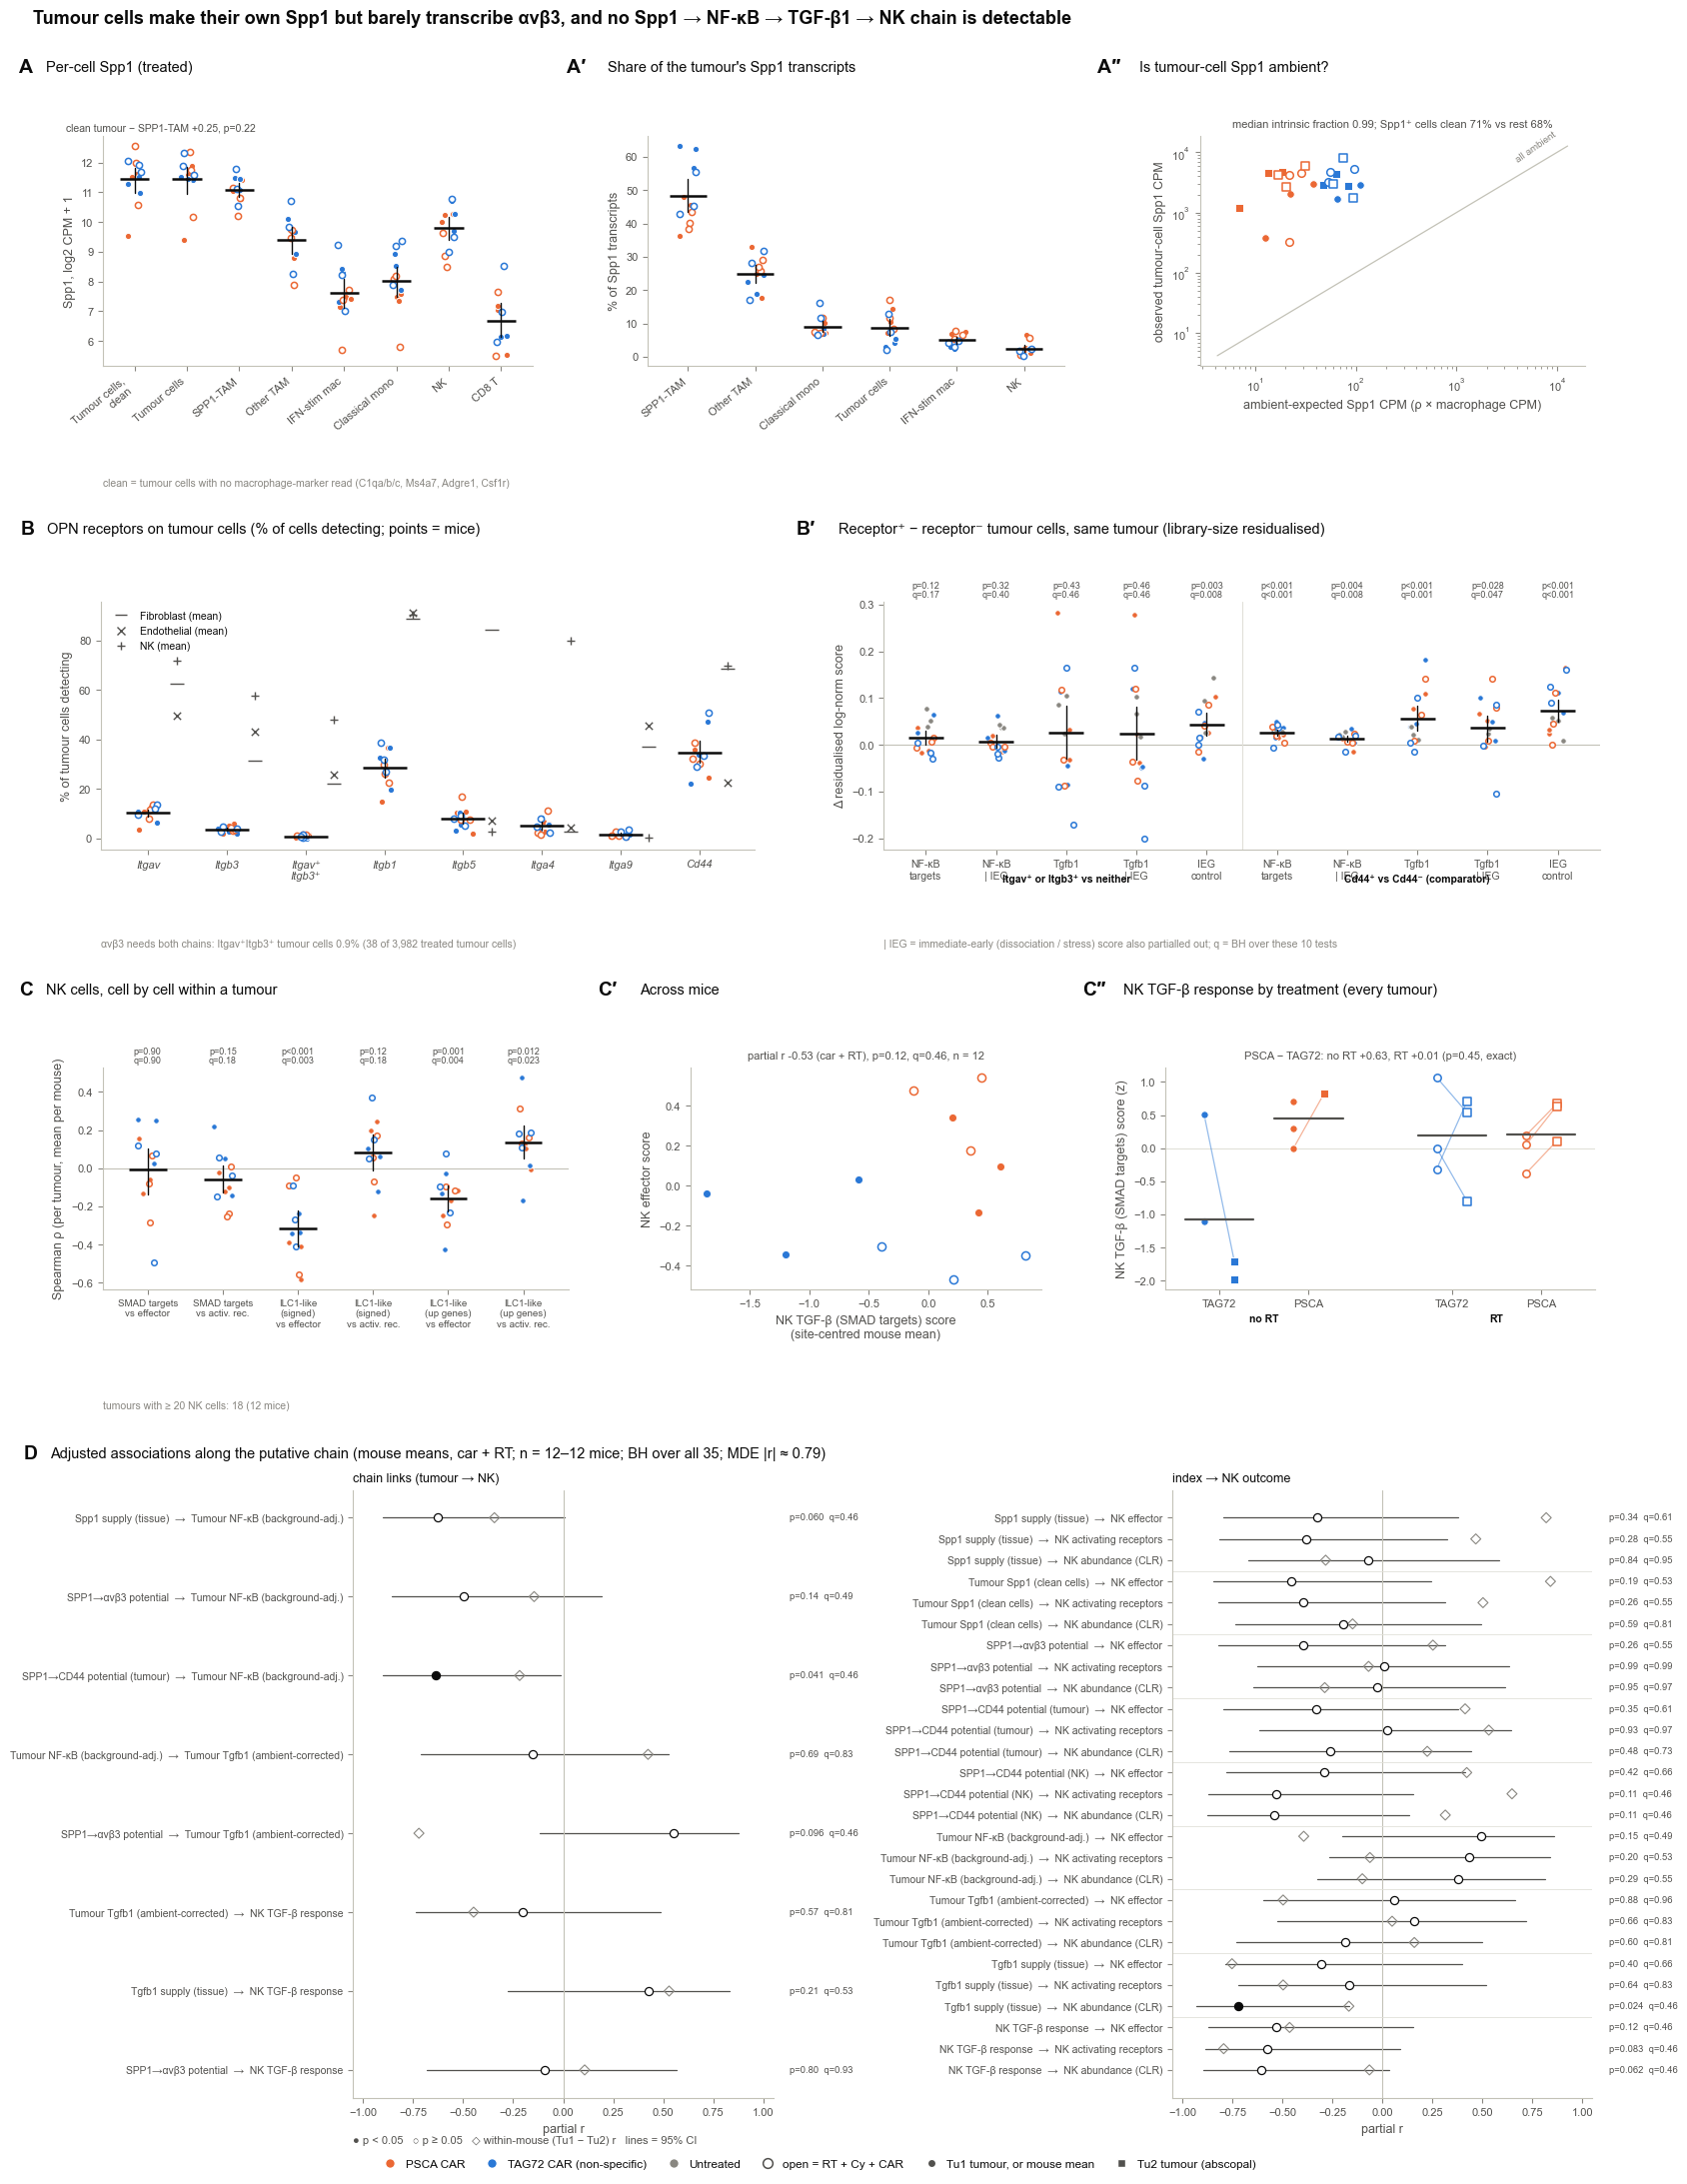

fig7 companion tables: 102 displayed statistics (9 panels), 508 source-data rows


In [9]:
ARM_OF_MOUSE = design.drop_duplicates("mouse").set_index("mouse").arm


def fmt_p(p):
    return "n/a" if not np.isfinite(p) else "p<0.001" if p < 0.001 else f"p={p:.3f}" if p < 0.1 else f"p={p:.2f}"


def fmt_q(q):
    return "" if not np.isfinite(q) else "q<0.001" if q < 0.001 else f"q={q:.3f}" if q < 0.1 else f"q={q:.2f}"


def dot(ax, x, y, arm, site=None, s=30, z=3):
    col = CAR_COL[CAR_OF[arm]]; rt = arm.startswith("RT")
    ax.scatter(np.atleast_1d(x), np.atleast_1d(y), s=s, marker=SITE_MARK.get(site, "o"), zorder=z,
               facecolor="white" if rt else col, edgecolor=col if rt else "white", linewidth=1.1 if rt else 0.7)


def mouse_strip(ax, values, x, jitter=0.13, s=28):
    g_ = np.random.default_rng(SEED + int(round(x * 100)))
    for mo, v in values.dropna().items():
        dot(ax, x + g_.uniform(-jitter, jitter), v, ARM_OF_MOUSE[mo], s=s)


def mean_ci(ax, x, m, lo, hi, w=0.28, color=INK):
    if not np.isfinite(m): return
    ax.plot([x - w, x + w], [m, m], color=color, lw=1.8, zorder=5, solid_capstyle="butt")
    ax.plot([x, x], [lo, hi], color=color, lw=1.0, zorder=5)


def boot_ci(v):
    v = v.dropna().values
    bt = v[rng.integers(0, len(v), (N_BOOT, len(v)))].mean(1)
    return v.mean(), np.percentile(bt, 2.5), np.percentile(bt, 97.5)


def top_note(ax, x, text, fs=7):
    ax.text(x, 1.01, text, transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=fs, color=INK2,
            linespacing=0.95)


def panel_label(sf, letter, title, x=0.0, y=1.0):
    sf.text(x + 0.004, y - 0.006, letter, fontsize=14, fontweight="bold", va="top", ha="left", color=INK)
    tr = mpl.transforms.offset_copy(sf.transSubfigure, fig=sf.figure, x=11 * len(letter) + 8, y=-1.5, units="points")
    sf.text(x + 0.004, y - 0.006, title, fontsize=10.5, va="top", ha="left", color=INK, transform=tr)


def under_label(ax, x, text, fs=7.5, bold=True):
    ax.annotate(text, (x, 0), xycoords=("data", "axes fraction"), xytext=(0, -(9 + fs * 1.15)), textcoords="offset points",
                ha="center", va="top", fontsize=fs, color=INK if bold else INK2, fontweight="bold" if bold else "normal",
                annotation_clip=False)


def legend_car_rt_site(fig, y=0.0):
    h = [Line2D([], [], marker="o", ls="", mfc=C_PSCA, mec="white", ms=7, label="PSCA CAR"),
         Line2D([], [], marker="o", ls="", mfc=C_TAG72, mec="white", ms=7, label="TAG72 CAR (non-specific)"),
         Line2D([], [], marker="o", ls="", mfc=C_NOTX, mec="white", ms=7, label="Untreated"),
         Line2D([], [], marker="o", ls="", mfc="white", mec=INK2, mew=1.1, ms=7, label="open = RT + Cy + CAR"),
         Line2D([], [], marker="o", ls="", mfc=INK2, mec="white", ms=6, label="Tu1 tumour, or mouse mean"),
         Line2D([], [], marker="s", ls="", mfc=INK2, mec="white", ms=6, label="Tu2 tumour (abscopal)")]
    fig.legend(handles=h, loc="lower center", bbox_to_anchor=(0.5, y), frameon=False, ncol=len(h), fontsize=8.5,
               handletextpad=0.3, columnspacing=1.3)


def mouse_vals(per_sample):
    v = per_sample.dropna(); v = v[v.index.isin(TREATED)]
    return v.groupby(mouse_of(v.index)).mean()


itgb3_t = RC[(RC.population == "Cancer_cell") & (RC.gene == "Itgb3")].iloc[0]
avb3_t = RC[(RC.population == "Cancer_cell") & (RC.gene == "Itgav_Itgb3")].iloc[0]
FIG7_TITLE = ("Tumour cells make their own Spp1 but barely transcribe αvβ3, and no Spp1 → NF-κB → TGF-β1 → NK chain is detectable"
              if AS.replicated.sum() == 0 and avb3_t.pct_mean < 5 else "SPP1-associated TGF-β / NK suppression: transcript-level tests")

fig = plt.figure(figsize=(16, 21))
R = fig.subfigures(4, 1, height_ratios=[0.9, 0.9, 0.9, 1.45], hspace=0.035)

# ---------- A
sA, sA2, sA3 = R[0].subfigures(1, 3, width_ratios=[0.34, 0.33, 0.33], wspace=0.02)
panel_label(sA, "A", "Per-cell Spp1 (treated)")
axA = sA.add_axes([0.16, 0.30, 0.80, 0.52])
A_P = ["tumour_clean", "Cancer_cell", "SPP1_TAM", "TAM_other", "IFN_stimulated_Mac", "Classical_Mono", "NK", "CD8_T"]
for i, p_ in enumerate(A_P):
    mv = mouse_vals(pb_level(p_, "Spp1")); mouse_strip(axA, mv, i, s=20)
    m, lo, hi = boot_ci(mv); mean_ci(axA, i, m, lo, hi)
    show_stat("7A", population=p_, statistic="per-cell Spp1, log2 CPM+1 (mean over treated mice)", value=m, ci_lo=lo, ci_hi=hi,
              n_mice=len(mv))
    show_source("7A", pd.DataFrame({"population": p_, "mouse": mv.index, "value": mv.values}))
axA.set_xticks(range(len(A_P)))
axA.set_xticklabels(["Tumour cells,\nclean" if p == "tumour_clean" else lab(p) for p in A_P], rotation=40, ha="right")
axA.set_ylabel("Spp1, log2 CPM + 1"); axA.set_xlim(-0.6, len(A_P) - 0.4)
ps_ = PAIR_SPP1["tumour_clean"]
top_note(axA, 0.5, f"clean tumour − SPP1-TAM {ps_['mean_diff']:+.2f}, {fmt_p(ps_['p_signflip'])}", fs=7.5)
show_stat("7A", population="tumour_clean minus SPP1_TAM", statistic="paired Δ per-cell Spp1 (log2 CPM), mean over mice",
          value=ps_["mean_diff"], ci_lo=ps_["ci_lo"], ci_hi=ps_["ci_hi"], n_mice=ps_["n_mice"], p_signflip=ps_["p_signflip"])
sA.text(0.16, 0.03, "clean = tumour cells with no macrophage-marker read (C1qa/b/c, Ms4a7, Adgre1, Csf1r)", fontsize=7.5, color=MUTED)

panel_label(sA2, "A′", "Share of the tumour's Spp1 transcripts")
axA2 = sA2.add_axes([0.16, 0.30, 0.80, 0.52])
A2_P = ["SPP1_TAM", "TAM_other", "Classical_Mono", "Cancer_cell", "IFN_stimulated_Mac", "NK"]
for i, p_ in enumerate(A2_P):
    mv = 100 * SHm[p_]; mouse_strip(axA2, mv, i, s=20)
    r = SRCT.loc[p_]; mean_ci(axA2, i, 100 * r.share_mean, 100 * r.share_ci_lo, 100 * r.share_ci_hi)
    show_stat("7A′", population=p_, statistic="% of tumour's Spp1 transcripts (mean over treated mice)", value=100 * r.share_mean,
              ci_lo=100 * r.share_ci_lo, ci_hi=100 * r.share_ci_hi, n_mice=int(r.n_mice))
    show_source("7A′", pd.DataFrame({"population": p_, "mouse": mv.index, "value": mv.values}))
axA2.set_xticks(range(len(A2_P))); axA2.set_xticklabels([lab(p) for p in A2_P], rotation=40, ha="right")
axA2.set_ylabel("% of Spp1 transcripts"); axA2.set_xlim(-0.6, len(A2_P) - 0.4)

panel_label(sA3, "A″", "Is tumour-cell Spp1 ambient?")
axA3 = sA3.add_axes([0.20, 0.30, 0.74, 0.52])
at = AMBT[AMBT.index.isin(TREATED)]
for s, r in at.iterrows():
    dot(axA3, r.Spp1_ambient_cpm, r.Spp1_obs_cpm, design.loc[s, "arm"], site=design.loc[s, "site"], s=30)
lim = [min(at.Spp1_ambient_cpm.min(), at.Spp1_obs_cpm.min()) * 0.6, max(at.Spp1_ambient_cpm.max(), at.Spp1_obs_cpm.max()) * 1.6]
axA3.plot(lim, lim, color=AXIS, lw=0.9); axA3.set_xscale("log"); axA3.set_yscale("log")
axA3.text(lim[1] * 0.8, lim[1] * 0.55, "all ambient", fontsize=7, color=MUTED, ha="right", rotation=35)
axA3.set_xlabel("ambient-expected Spp1 CPM (ρ × macrophage CPM)"); axA3.set_ylabel("observed tumour-cell Spp1 CPM")
cs_ = CLEAN.set_index("gene").loc["Spp1"]
med_if = AMBT.loc[at.index, "Spp1_intrinsic"].median()
axA3.set_title(f"median intrinsic fraction {med_if:.2f}; Spp1⁺ cells clean {cs_.clean_pct:.0f}% vs rest {cs_.rest_pct:.0f}%",
               fontsize=8, color=INK2)
show_stat("7A″", population="Cancer_cell", statistic="median intrinsic fraction of tumour Spp1 (treated tumours)", value=med_if,
          n_samples=len(at))
show_stat("7A″", population="Cancer_cell", statistic="% Spp1+ tumour cells, clean minus rest (mean over mice)",
          value=cs_.mean_diff, ci_lo=cs_.ci_lo, ci_hi=cs_.ci_hi, n_mice=cs_.n_mice, p_signflip=cs_.p_signflip)
show_source("7A″", at[["rho", "Spp1_obs_cpm", "Spp1_ambient_cpm", "Spp1_intrinsic", "Spp1_clean_cpm"]].reset_index()
            .assign(arm=lambda d: design.loc[d["sample"], "arm"].values, site=lambda d: design.loc[d["sample"], "site"].values))

# ---------- B
sB, sB2 = R[1].subfigures(1, 2, width_ratios=[0.48, 0.52], wspace=0.02)
panel_label(sB, "B", "OPN receptors on tumour cells (% of cells detecting; points = mice)")
axB = sB.add_axes([0.11, 0.25, 0.86, 0.56])
srcB = pd.concat(rc_src, ignore_index=True)
B_G = ["Itgav", "Itgb3", "Itgav_Itgb3", "Itgb1", "Itgb5", "Itga4", "Itga9", "Cd44"]
REF = {"Fibroblast": ("_", 90), "Endothelial": ("x", 28), "NK": ("+", 40)}
for i, g in enumerate(B_G):
    mv = srcB[srcB.population == "Cancer_cell"].set_index("mouse")[g]; mouse_strip(axB, mv, i, s=20)
    r = RC[(RC.population == "Cancer_cell") & (RC.gene == g)].iloc[0]
    mean_ci(axB, i, r.pct_mean, r.ci_lo, r.ci_hi)
    for ref, (mk, sz) in REF.items():
        rr_ = RC[(RC.population == ref) & (RC.gene == g)]
        if len(rr_): axB.scatter(i + 0.36, rr_.pct_mean.iloc[0], marker=mk, color=INK2, s=sz, lw=1.0, zorder=4)
    show_stat("7B", population="Cancer_cell", gene=g, statistic="% tumour cells detecting (mean over treated mice)", value=r.pct_mean,
              ci_lo=r.ci_lo, ci_hi=r.ci_hi, n_mice=r.n_mice, cells_positive=r.cells_positive, cells_total=r.cells_total)
    for ref in REF:
        rr_ = RC[(RC.population == ref) & (RC.gene == g)]
        if len(rr_): show_stat("7B", population=ref, gene=g, statistic="% cells detecting (reference population)",
                               value=rr_.pct_mean.iloc[0], n_mice=int(rr_.n_mice.iloc[0]))
axB.set_xticks(range(len(B_G)))
axB.set_xticklabels([{"Itgav_Itgb3": "Itgav⁺\nItgb3⁺"}.get(g, g) for g in B_G], fontstyle="italic")
axB.set_ylabel("% of tumour cells detecting"); axB.set_xlim(-0.6, len(B_G) - 0.3)
axB.legend(handles=[Line2D([], [], marker=mk, ls="", color=INK2, ms=6 if mk != "_" else 9, label=f"{lab(ref)} (mean)")
                    for ref, (mk, _) in REF.items()], loc="upper left", fontsize=7.5, frameon=False)
sB.text(0.11, 0.03, f"αvβ3 needs both chains: Itgav⁺Itgb3⁺ tumour cells {avb3_t.pct_mean:.1f}% "
        f"({int(avb3_t.cells_positive)} of {int(avb3_t.cells_total):,} treated tumour cells)", fontsize=7.5, color=MUTED)
show_source("7B", srcB)

panel_label(sB2, "B′", "Receptor⁺ − receptor⁻ tumour cells, same tumour (library-size residualised)")
axB2 = sB2.add_axes([0.11, 0.25, 0.87, 0.56])
srcB2 = pd.concat(wt_src, ignore_index=True)
RO = ["NFkB_targets", "NFkB_targets_adjIEG", "Tgfb1_ln", "Tgfb1_ln_adjIEG", "IEG_dissociation"]
RO_LAB = {"NFkB_targets": "NF-κB\ntargets", "NFkB_targets_adjIEG": "NF-κB\n| IEG", "Tgfb1_ln": "Tgfb1",
          "Tgfb1_ln_adjIEG": "Tgfb1\n| IEG", "IEG_dissociation": "IEG\ncontrol"}
x_, xl = 0, []
for rec in ["avb3_chain", "cd44_pos"]:
    for k in RO:
        mv = srcB2[(srcB2.receptor == rec) & (srcB2.readout == k)].set_index("mouse").value
        mouse_strip(axB2, mv, x_, s=16)
        r = WT[(WT.receptor == rec) & (WT.readout == k)].iloc[0]
        mean_ci(axB2, x_, r.mean_diff, r.ci_lo, r.ci_hi, w=0.25)
        top_note(axB2, x_, f"{fmt_p(r.p_signflip)}\n{fmt_q(r.q)}", fs=6.5)
        show_stat("7B′", receptor=rec, readout=k, statistic="receptor+ minus receptor− tumour cells, residualised, mean over mice",
                  value=r.mean_diff, ci_lo=r.ci_lo, ci_hi=r.ci_hi, n_mice=r.n_mice, p_signflip=r.p_signflip, q=r.q,
                  cells_pos=r.cells_pos, cells_total=r.cells_total)
        xl.append(RO_LAB[k]); x_ += 1
    under_label(axB2, x_ - 3, {"avb3_chain": "Itgav⁺ or Itgb3⁺ vs neither", "cd44_pos": "Cd44⁺ vs Cd44⁻ (comparator)"}[rec])
axB2.axvline(len(RO) - 0.5, color=GRID, lw=0.8); axB2.axhline(0, color=AXIS, lw=0.8, zorder=1)
axB2.set_xticks(range(len(xl))); axB2.set_xticklabels(xl, fontsize=7.5); axB2.set_xlim(-0.6, len(xl) - 0.4)
axB2.set_ylabel("Δ residualised log-norm score")
sB2.text(0.11, 0.03, "| IEG = immediate-early (dissociation / stress) score also partialled out; q = BH over these 10 tests",
         fontsize=7.5, color=MUTED)
show_source("7B′", srcB2)

# ---------- C
sC, sC2, sC3 = R[2].subfigures(1, 3, width_ratios=[0.36, 0.30, 0.34], wspace=0.02)
panel_label(sC, "C", "NK cells, cell by cell within a tumour")
axC = sC.add_axes([0.15, 0.30, 0.82, 0.50])
srcC = pd.concat(wc_src, ignore_index=True)
TG_LAB = {"TGFb_SMAD_targets": "SMAD targets", "NK_TGFb_imprint": "ILC1-like\n(signed)", "NK_TGFb_up": "ILC1-like\n(up genes)"}
xl = []
for i, ((a, b), dd) in enumerate(WC.groupby(["tgfb_readout", "nk_readout"], sort=False)):
    mv = srcC[(srcC.tgfb_readout == a) & (srcC.nk_readout == b)].set_index("mouse").value
    mouse_strip(axC, mv, i, s=16)
    r = dd.iloc[0]
    mean_ci(axC, i, r.mean_diff, r.ci_lo, r.ci_hi, w=0.25)
    top_note(axC, i, f"{fmt_p(r.p_signflip)}\n{fmt_q(r.q)}", fs=6.5)
    show_stat("7C", tgfb_readout=a, nk_readout=b, statistic="within-tumour NK Spearman rho (residualised), mean over mice",
              value=r.mean_diff, ci_lo=r.ci_lo, ci_hi=r.ci_hi, n_mice=r.n_mice, p_signflip=r.p_signflip, q=r.q)
    xl.append(f"{TG_LAB[a]}\nvs {'effector' if b == 'effector' else 'activ. rec.'}")
axC.axhline(0, color=AXIS, lw=0.8); axC.set_xticks(range(len(xl))); axC.set_xticklabels(xl, fontsize=7, rotation=0)
axC.set_xlim(-0.6, len(xl) - 0.4); axC.set_ylabel("Spearman ρ (per tumour, mean per mouse)")
sC.text(0.15, 0.03, f"tumours with ≥ {MIN_CELLS_STATE} NK cells: {int(WC.n_samples.max())} ({int(WC.n_mice.max())} mice)",
        fontsize=7.5, color=MUTED)
show_source("7C", srcC)

panel_label(sC2, "C′", "Across mice")
axC2 = sC2.add_axes([0.20, 0.30, 0.74, 0.50])
mx, my = mouse_means(NK_SC["TGFb_SMAD_targets"]), mouse_means(NK_SC["effector"])
mi = mx.index.intersection(my.index)
for mo in mi: dot(axC2, mx.loc[mo, "v"], my.loc[mo, "v"], mx.loc[mo, "arm"], s=34)
rr_ = AS[(AS.predictor == "NK TGF-β response") & (AS.outcome == "NK effector")].iloc[0]
axC2.set_xlabel("NK TGF-β (SMAD targets) score\n(site-centred mouse mean)"); axC2.set_ylabel("NK effector score")
axC2.set_title(f"partial r {rr_.partial_r:+.2f} (car + RT), {fmt_p(rr_.p_mouse)}, {fmt_q(rr_.q_mouse)}, n = {int(rr_.n_mice)}",
               fontsize=8, color=INK2)
show_source("7C′", pd.DataFrame({"mouse": mi, "x": mx.loc[mi, "v"].values, "y": my.loc[mi, "v"].values, "arm": mx.loc[mi, "arm"].values}))
show_stat("7C′", predictor="NK TGF-β response", outcome="NK effector", statistic="mouse-level partial r (car + RT)",
          value=rr_.partial_r, ci_lo=rr_.r_ci_lo, ci_hi=rr_.r_ci_hi, n_mice=rr_.n_mice, p=rr_.p_mouse, q=rr_.q_mouse)

panel_label(sC3, "C″", "NK TGF-β response by treatment (every tumour)")
axC3 = sC3.add_axes([0.16, 0.30, 0.80, 0.50])
v = NK_SC["TGFb_SMAD_targets"]
XP = {"CyT72": 0.0, "CyPSCA": 1.0, "RTCyT72": 2.6, "RTCyPSCA": 3.6}
for arm, x0 in XP.items():
    smp = [s for s in v.index if design.loc[s, "arm"] == arm]
    for mo, g in design.loc[smp].groupby("mouse"):
        if set(g.site) == {1, 2}:
            y1, y2 = v[g.index[g.site == 1][0]], v[g.index[g.site == 2][0]]
            axC3.plot([x0 - 0.17, x0 + 0.17], [y1, y2], color=CAR_COL[CAR_OF[arm]], lw=0.9, alpha=0.5, zorder=2)
    for s in smp: dot(axC3, XP[arm] + (-0.17 if design.loc[s, "site"] == 1 else 0.17), v[s], arm, site=design.loc[s, "site"], s=28)
    axC3.plot([x0 - 0.38, x0 + 0.38], [v[smp].mean()] * 2, color=INK2, lw=1.6, zorder=4)
axC3.set_xticks(list(XP.values())); axC3.set_xticklabels(["TAG72", "PSCA", "TAG72", "PSCA"])
under_label(axC3, 0.5, "no RT"); under_label(axC3, 3.1, "RT")
axC3.axhline(0, color=GRID, lw=0.8, zorder=0); axC3.set_ylabel("NK TGF-β (SMAD targets) score (z)")
tp = TX[(TX.group == "NK") & (TX.measure == "TGFb_SMAD_targets") & (TX.effect == "PSCA")].iloc[0]
axC3.set_title(f"PSCA − TAG72: no RT {tp.d_1:+.2f}, RT {tp.d_2:+.2f} ({fmt_p(tp.p_main)}, exact)", fontsize=8, color=INK2)
show_stat("7C″", group="NK", measure="TGFb_SMAD_targets", statistic="PSCA − TAG72 (site-matched), exact relabelling",
          value=tp.main, d_noRT=tp.d_1, d_RT=tp.d_2, p=tp.p_main, q=tp.q)
show_source("7C″", pd.DataFrame({"sample": v.index, "value": v.values, "arm": design.loc[v.index, "arm"].values,
                                 "site": design.loc[v.index, "site"].values}))

# ---------- D
sD = R[3]
panel_label(sD, "D", f"Adjusted associations along the putative chain (mouse means, car + RT; n = {int(AS.n_mice.min())}–"
                     f"{int(AS.n_mice.max())} mice; BH over all {len(AS)}; MDE |r| ≈ {AS.mde_r.median():.2f})")
axs = sD.subplots(1, 2, gridspec_kw=dict(left=0.21, right=0.985, top=0.93, bottom=0.08, wspace=0.95,
                                         width_ratios=[1, 1]))
for ax, kind, ttl in [(axs[0], "chain link", "chain links (tumour → NK)"), (axs[1], "index -> NK outcome", "index → NK outcome")]:
    d = AS[AS.kind == kind].reset_index(drop=True)
    yy = np.arange(len(d))[::-1]
    for y_, (_, r) in zip(yy, d.iterrows()):
        if not np.isfinite(r.partial_r): continue
        ax.plot([r.r_ci_lo, r.r_ci_hi], [y_, y_], color=INK2, lw=0.9)
        ax.scatter(r.partial_r, y_, s=34, color=INK if r.p_mouse < 0.05 else "white", edgecolor=INK, lw=0.9, zorder=3)
        if np.isfinite(r.get("r_within", np.nan)):
            ax.scatter(r.r_within, y_, s=26, marker="D", facecolor="none", edgecolor=MUTED, lw=0.8, zorder=2)
        ax.text(1.04, y_, f"{fmt_p(r.p_mouse)}  {fmt_q(r.q_mouse)}", transform=ax.get_yaxis_transform(), va="center",
                fontsize=6.8, color=INK2)
        show_stat("7D", predictor=r.predictor, outcome=r.outcome, kind=r.kind, statistic="mouse-level partial r (car + RT)",
                  value=r.partial_r, ci_lo=r.r_ci_lo, ci_hi=r.r_ci_hi, n_mice=r.n_mice, p=r.p_mouse, q=r.q_mouse,
                  r_within_mouse=r.get("r_within"), p_within=r.get("p_within"), r_sample_level=r.partial_r_sample,
                  p_sample_level=r.p_sample, lmm_beta=r.lmm_beta, lmm_p=r.lmm_p, lmm_converged=r.get("lmm_converged"),
                  lomo_flips=r.get("lomo_flips"), mde_r=r.mde_r, replicated=r.replicated)
    ax.axvline(0, color=AXIS, lw=0.8); ax.set_xlim(-1.05, 1.05)
    ax.set_yticks(yy); ax.set_yticklabels(d.predictor + "  →  " + d.outcome, fontsize=7.5)
    ax.set_title(ttl, fontsize=9, color=INK, loc="left"); ax.set_xlabel("partial r")
    if kind != "chain link":
        for k_ in range(1, len(d) // 3): ax.axhline(len(d) - 3 * k_ - 0.5, color=GRID, lw=0.6)
sD.text(0.21, 0.015, "● p < 0.05   ○ p ≥ 0.05   ◇ within-mouse (Tu1 − Tu2) r   lines = 95% CI", fontsize=8, color=INK2)
show_source("7D", AS.rename(columns={"partial_r": "value"}))

legend_car_rt_site(fig, y=-0.012)
fig.suptitle(FIG7_TITLE, x=0.01, ha="left", y=1.022, fontsize=13, fontweight="bold", color=INK)
save_figure(fig, "fig7_spp1_tgfb_nk")
plt.show()
STATS7 = pd.DataFrame(DISPLAYED); STATS7.to_csv(FIG/"fig7_spp1_tgfb_nk_displayed_stats.csv", index=False)
SRC7 = pd.concat(SOURCE, ignore_index=True); SRC7.to_csv(FIG/"fig7_spp1_tgfb_nk_source_data.csv", index=False)
print(f"fig7 companion tables: {len(STATS7)} displayed statistics ({STATS7.panel.nunique()} panels), {len(SRC7)} source-data rows")

## 10. Summary

In [10]:
def wt(rec, k): return WT[(WT.receptor == rec) & (WT.readout == k)].iloc[0]


def wc(a, b): return WC[(WC.tgfb_readout == a) & (WC.nk_readout == b)].iloc[0]


tim_ = TI.groupby(mouse_of(TI.index)).mean()
print("=" * 110); print("SUMMARY — report these back"); print("=" * 110)
print(f"[data] {len(meta):,} cells, {len(design)} tumours, {design.mouse.nunique()} mice ({design.loc[TREATED].mouse.nunique()} treated); "
      f"mouse = unit. NK: {int(COV.loc['NK','treated_mice_ge10'])} treated mice with >= 10 cells (median "
      f"{COV.loc['NK','median_cells_per_sample']:.0f} / tumour).")

print("\n1. THREE STRONGEST FINDINGS")
print(f"  (i) Tumour cells transcribe their own Spp1 (Shen S1, the tumour-source premise, holds here): median intrinsic fraction "
      f"{med_if:.2f}; clean tumour cells (no macrophage-marker read) {cs_.clean_pct:.0f}% Spp1+ vs {cs_.rest_pct:.0f}% in the rest; "
      f"per-cell level vs SPP1-TAMs {ps_['mean_diff']:+.2f} log2 [{ps_['ci_lo']:+.2f},{ps_['ci_hi']:+.2f}]. By abundance, macrophages still "
      f"supply {100*tim_.macrophage_share.mean():.0f}% of the tumour's Spp1 and tumour cells {100*tim_.tumour_intrinsic_share.mean():.1f}%.")
print(f"  (ii) The receptor Shen identified is barely transcribed by tumour cells: Itgb3 {itgb3_t.pct_mean:.1f}% "
      f"[{itgb3_t.ci_lo:.1f},{itgb3_t.ci_hi:.1f}], Itgav {RC[(RC.population=='Cancer_cell')&(RC.gene=='Itgav')].pct_mean.iloc[0]:.1f}%, "
      f"both {avb3_t.pct_mean:.1f}% ({int(avb3_t.cells_positive)} cells) — vs "
      f"{RC[(RC.population=='Endothelial')&(RC.gene=='Itgav_Itgb3')].pct_mean.iloc[0]:.0f}% of endothelial, "
      f"{RC[(RC.population=='Fibroblast')&(RC.gene=='Itgav_Itgb3')].pct_mean.iloc[0]:.0f}% of fibroblasts and "
      f"{RC[(RC.population=='NK')&(RC.gene=='Itgav_Itgb3')].pct_mean.iloc[0]:.0f}% of NK cells. Cd44 is on "
      f"{RC[(RC.population=='Cancer_cell')&(RC.gene=='Cd44')].pct_mean.iloc[0]:.0f}% of tumour cells.")
a_, a2_, c_, c2_ = wt("avb3_chain", "NFkB_targets"), wt("avb3_chain", "NFkB_targets_adjIEG"), wt("cd44_pos", "NFkB_targets"), wt("cd44_pos", "NFkB_targets_adjIEG")
print(f"  (iii) No step of the Spp1 -> NF-kB -> TGF-beta1 -> NK chain is supported: {int(AS.replicated.sum())} of {len(AS)} associations replicate "
      f"(min q {AS.q_mouse.min():.2f}); Spp1 supply vs tumour NF-kB r = "
      f"{AS[(AS.predictor=='Spp1 supply (tissue)')&(AS.outcome.str.startswith('Tumour NF'))].partial_r.iloc[0]:+.2f} (opposite to the "
      f"mechanism); within tumours, Itgav/Itgb3+ cells: NF-kB {a_.mean_diff:+.3f} (p={a_.p_signflip:.2f}), IEG-adjusted {a2_.mean_diff:+.3f} "
      f"(p={a2_.p_signflip:.2f}).")

print("\n2. FDR-SIGNIFICANT AND REPLICATED")
print(f"  Spp1 tumour-intrinsic (ambient model + clean-cell check agree)")
for _, r in WT[(WT.q < 0.05) & (WT.lomo_flips == 0)].iterrows():
    print(f"  within tumour, {r.receptor}: {r.readout} {r.mean_diff:+.3f} q={r.q:.3f} ({100*r.frac_mice_same_sign:.0f}% of mice same sign)"
          + ("   [control]" if r.readout == "IEG_dissociation" else ""))
for _, r in WC[(WC.q < 0.05) & (WC.lomo_flips == 0)].iterrows():
    print(f"  NK within tumour: {r.tgfb_readout} vs {r.nk_readout} rho {r.mean_diff:+.3f} q={r.q:.3f}")
print("  treatment (exact relabelling, both strata/backgrounds, q<0.10, no LOMO flip): " + ("; ".join(
    f"{r.effect}: {r.measure} @ {lab(r.group)} {r.main_sd:+.1f} SD" for _, r in TX[TX.replicated].iterrows()) or "none"))
print("  02 DESeq2 replicated (tumour / NK / CD8 / SPP1-TAM): " + (", ".join(
    f"{r.effect}:{r.gene}@{lab(r.group)}({r.lfc_1:+.1f}/{r.lfc_2:+.1f})" for _, r in
    DER[DER.replicated & DER.group.isin(["Cancer_cell", "NK", "CD8_T", "cytotoxic_lymph", "SPP1_TAM"])].iterrows()) or "none"))
print(f"  associations (Fig 7D): {int(AS.replicated.sum())} replicated")

print("\n3. SUGGESTIVE OR INCONCLUSIVE")
for _, r in AS[AS.p_mouse < 0.10].sort_values("p_mouse").iterrows():
    print(f"  {r.predictor} -> {r.outcome}: r={r.partial_r:+.2f} p={r.p_mouse:.3f} q={r.q_mouse:.2f}; within-mouse "
          f"{r.get('r_within', np.nan):+.2f}; LMM p={r.lmm_p:.3f}")
cd44_x = AS[(AS.predictor == "SPP1→CD44 potential (tumour)") & AS.outcome.str.startswith("Tumour NF")].iloc[0]
print(f"  Cd44+ tumour cells carry more NF-kB-target transcript ({c_.mean_diff:+.3f}, q={c_.q:.3f}) and more IEG; with IEG partialled out "
      f"the excess {'persists' if c2_.q < 0.05 else 'is lost'} ({c2_.mean_diff:+.3f}, q={c2_.q:.3f}). Cd44 is itself an NF-kB target gene "
      f"and across mice the SPP1->CD44 potential runs the other way (r={cd44_x.partial_r:+.2f} vs tumour NF-kB), so this is "
      f"co-regulation within a cell state, not evidence that SPP1 signals through CD44")
up_e, sm_e = wc("NK_TGFb_up", "effector"), wc("TGFb_SMAD_targets", "effector")
print(f"  NK: ILC1-like features track fewer cytotoxic transcripts within tumours (signed imprint rho "
      f"{wc('NK_TGFb_imprint','effector').mean_diff:+.2f}; up genes Itga1/Itgae/Tnfsf10 alone {up_e.mean_diff:+.2f}, q={up_e.q:.3f}), "
      f"but canonical SMAD targets do not ({sm_e.mean_diff:+.2f}, q={sm_e.q:.2f}) -> a phenotype consistent with the TGF-beta-driven "
      f"NK -> ILC1-like literature, not a measured TGF-beta response; activating receptors move the other way "
      f"({wc('NK_TGFb_up','NK_activating').mean_diff:+.2f})")
print(f"  LMM (1 | mouse) converged in {int(AS.lmm_converged.sum())} of {len(AS)} fits")
sg = TX[(TX.agree == True) & (TX.p_main < 0.05) & ~TX.replicated]
print("  sign-agreeing treatment effects at p<0.05 not passing q / LOMO: " + ("; ".join(
    f"{r.effect}: {r.measure} @ {lab(r.group)} {r.main:+.2f} (p={r.p_main:.3f})" for _, r in sg.iterrows()) or "none"))

print("\n4. QC / DATA-COVERAGE CONCERNS")
print(f"  NK pseudobulk in {int(COV.loc['NK','treated_samples_ge10'])} treated tumours / {int(COV.loc['NK','treated_mice_ge10'])} mice; "
      f"CD8 T {int(COV.loc['CD8_T','treated_samples_ge10'])} / {int(COV.loc['CD8_T','treated_mice_ge10'])}; association MDE |r| "
      f"{AS.mde_r.min():.2f}; within-mouse tests on {int(AS.n_mice_within.max())} mice at most")
print(f"  only {int(avb3_t.cells_positive)} Itgav+Itgb3+ tumour cells in all treated tumours: a within-cell αvβ3-specific test is impossible, "
      f"so the integrin contrast uses 'either chain'; Itgb3+ fraction MDE ~{ITGB3_MDE_PP:.0f} pp")
print(f"  Spp1 is detected in {COV.loc['NK','pct_Spp1']:.0f}% of NK and {COV.loc['CD8_T','pct_Spp1']:.0f}% of CD8 T cells — mostly spill-over; "
      f"never read lymphocyte Spp1 as their own")
print("  NF-kB targets and IEG genes co-move (dissociation / handling), and PSCA lowers both in tumour cells together; tumour NF-kB in the "
      "associations is background-adjusted for this reason")
print(f"  LMM (1 | mouse) converged in {int(AS.lmm_converged.sum())} of {len(AS)} fits at 12 mice (variance at the boundary); a check only")
print("  Nothing here measures OPN protein, integrin activation, p65 phosphorylation, TGF-beta1 secretion / activation or NK killing")

print("\n5. WHAT THE RESULTS PERMIT US TO CLAIM")
print("  * Tumour cells in this model are a genuine, per-cell high-level Spp1 source (macrophages dominate by number) — the premise of "
      "tumour-derived OPN is compatible with the data.")
if avb3_t.pct_mean < 5:
    print("  * The receptor step is not supported at transcript level: tumour cells rarely transcribe Itgb3, and Itgav/Itgb3-positive "
          "tumour cells show no NF-kB or Tgfb1 excess. Integrin protein could still be present; RNA cannot show it.")
if AS.replicated.sum() == 0:
    print("  * No adjusted mouse-level association links Spp1 supply, αvβ3 potential, tumour NF-kB, tumour or tissue Tgfb1, or NK TGF-beta "
          "response to weaker NK effector programs. With 12 mice only |r| > ~0.8 is detectable — inconclusive, not a refutation.")
print("  * Swapping in CD44 as the receptor does not rescue the chain: Cd44+ tumour cells carry more NF-kB-target transcript within a "
      "tumour, but Cd44 is an NF-kB target itself and tumours with more SPP1->CD44 potential have LESS tumour NF-kB across mice.")
print("  * Within tumours, ILC1-like NK cells carry fewer cytotoxic transcripts, but no canonical TGF-beta (SMAD-target) response tracks NK "
      "effector programs within or across mice, so NK suppression by TGF-beta cannot be read from these data.")
print("  * Overall the Shen mechanism is not substantiated in this single-cell dataset. Testing it needs OPN and integrin β3 protein, "
      "p-p65, active TGF-β1 and NK function in this model.")
print(f"\n[files] {T08}/08_*.csv | {FIG}/fig7_spp1_tgfb_nk.(pdf|svg|png), _displayed_stats.csv, _source_data.csv")
print("=" * 110)

SUMMARY — report these back
[data] 93,548 cells, 29 tumours, 15 mice (12 treated); mouse = unit. NK: 12 treated mice with >= 10 cells (median 32 / tumour).

1. THREE STRONGEST FINDINGS
  (i) Tumour cells transcribe their own Spp1 (Shen S1, the tumour-source premise, holds here): median intrinsic fraction 0.99; clean tumour cells (no macrophage-marker read) 71% Spp1+ vs 68% in the rest; per-cell level vs SPP1-TAMs +0.25 log2 [-0.15,+0.61]. By abundance, macrophages still supply 78% of the tumour's Spp1 and tumour cells 8.6%.
  (ii) The receptor Shen identified is barely transcribed by tumour cells: Itgb3 3.8% [3.1,4.5], Itgav 10.4%, both 0.9% (38 cells) — vs 26% of endothelial, 22% of fibroblasts and 48% of NK cells. Cd44 is on 35% of tumour cells.
  (iii) No step of the Spp1 -> NF-kB -> TGF-beta1 -> NK chain is supported: 0 of 35 associations replicate (min q 0.46); Spp1 supply vs tumour NF-kB r = -0.63 (opposite to the mechanism); within tumours, Itgav/Itgb3+ cells: NF-kB +0.014 (p=0.